In [1]:
import time
import zipfile
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)
from gensim.models import Word2Vec
from sklearn.svm import LinearSVC
from sklearn.metrics.pairwise import cosine_similarity
from preprocessing import TextPreprocessor

LAB_DIR = Path(r"D:\Study\Study_Class\Semester_7\NLP\Lab\lab04")
DATA_PATH = LAB_DIR.parent / "data" / "archive.zip"

RANDOM_SEED = 2026
TRAIN_RATIO = 0.6
VALID_RATIO = 0.2
TEST_RATIO = 0.2


if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

print("Dataset:", DATA_PATH)

c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (7.4.3)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Dataset: D:\Study\Study_Class\Semester_7\NLP\Lab\data\archive.zip


In [2]:
# Hàm dùng chung: metrics, timing và visualization.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

LABEL_ORDER = ["negative", "positive"]


def compute_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=LABEL_ORDER
    ).ravel()
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label="positive", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label="positive", zero_division=0
        ),
        "F1": f1_score(y_true, y_pred, pos_label="positive", zero_division=0),
        "Macro F1": f1_score(
            y_true, y_pred, labels=LABEL_ORDER, average="macro", zero_division=0
        ),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)
    }


def fit_pipeline_with_timing(model, texts, labels):
    """Tách thời gian fit TF-IDF và classifier; không tính predict."""
    start = time.perf_counter()
    train_vectors = model.named_steps["tfidf"].fit_transform(texts)
    feature_time = time.perf_counter() - start

    start = time.perf_counter()
    model.named_steps["classifier"].fit(train_vectors, labels)
    classifier_time = time.perf_counter() - start
    return {
        "Feature fit time (s)": feature_time,
        "Classifier fit time (s)": classifier_time,
        "Training time (s)": feature_time + classifier_time
    }


def show_confusion_matrices(y_true, predictions, title):
    """Hàng là nhãn đúng, cột là nhãn dự đoán; mỗi ô là số mẫu."""
    matrices = {
        name: confusion_matrix(y_true, y_pred, labels=LABEL_ORDER)
        for name, y_pred in predictions.items()
    }
    ncols = 2 if len(matrices) == 4 else min(3, len(matrices))
    nrows = (len(matrices) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(5 * ncols, 4.5 * nrows), squeeze=False
    )
    vmax = max(matrix.max() for matrix in matrices.values())
    for ax, (name, matrix) in zip(axes.ravel(), matrices.items()):
        ConfusionMatrixDisplay(
            confusion_matrix=matrix, display_labels=LABEL_ORDER
        ).plot(
            ax=ax, cmap="Blues", values_format="d", colorbar=False,
            im_kw={"vmin": 0, "vmax": vmax}
        )
        ax.set_title(name, fontsize=10)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
    for ax in axes.ravel()[len(matrices):]:
        ax.set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def show_result_comparison(table, labels, title, metrics=("F1", "Training time (s)")):
    """So sánh các kết quả đã tính trong notebook."""
    fig, axes = plt.subplots(
        1, len(metrics), figsize=(5 * len(metrics), 4), squeeze=False
    )
    colors = ["steelblue", "seagreen", "darkorange", "slateblue"]
    positions = np.arange(len(table))
    for ax, metric in zip(axes.ravel(), metrics):
        values = table[metric].to_numpy()
        bars = ax.bar(positions, values, color=colors[:len(table)])
        ax.set_xticks(positions, labels)
        ax.set_ylabel(metric)
        ax.set_title(metric)
        if metric in {"F1", "Macro F1", "Accuracy", "Precision", "Recall"}:
            ax.set_ylim(0, 1.08)
            value_format = "%.4f"
        else:
            ax.set_ylim(0, max(float(values.max()) * 1.2, 1))
            value_format = "%.0f" if metric == "Vocabulary" else "%.2f"
        ax.bar_label(bars, fmt=value_format, padding=3)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

In [3]:
with zipfile.ZipFile(DATA_PATH) as z:
    print(z.namelist())
    with z.open("IMDB Dataset.csv") as f:
        df = pd.read_csv(f)

df.head()

['IMDB Dataset.csv']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Các nhận xét dưới đây dựa trên lần chạy seed 2026 đang có trong notebook, không phải dự đoán trước experiment. Precision, recall và F1 được tính cho lớp positive; Macro F1 là trung bình F1 của hai lớp. Phần ablation sử dụng validation, các bảng model cuối sử dụng test, còn S1/S2/S3 và Application là ví dụ minh họa.

Kiểm tra số học cho thấy cả 10 dòng metrics trong `results.csv` khớp với TN/FP/FN/TP, tổng support mỗi tập đánh giá là 9.916 và thời gian tổng bằng thời gian fit representation cộng fit classifier. Các cell có nội dung đã chạy theo thứ tự 1–55, không có traceback. Kết luận bên dưới áp dụng cho split và cấu hình này; không xem một lần chạy là bằng chứng rằng một phương pháp luôn tốt hơn phương pháp khác.

# Experiment 1 — Dataset inspection

Number of samples: 50000
Number of classes: 2

Class distribution:
          count  percentage
label                      
positive  25000        50.0
negative  25000        50.0

Missing text: 0
Missing label: 0
Duplicate texts: 418

Document length:
Mean: 228.87
Median: 171.0
Min: 4
Max: 2459


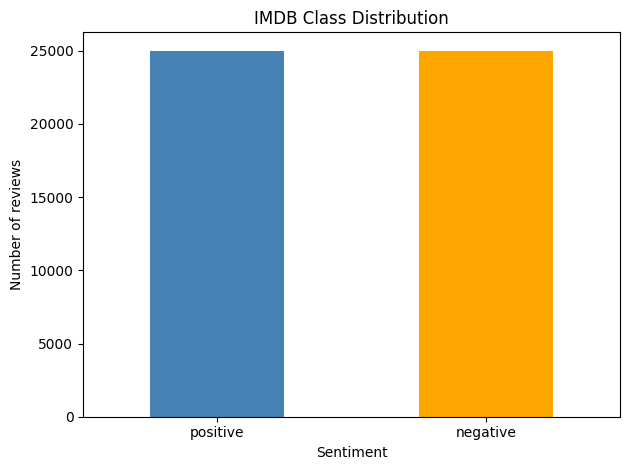

In [4]:
df = df.rename(columns={
    "review": "text", 
    "sentiment": "label"
    })

df["text_clean"] = (
    df["text"]
    .astype("string")
    .str.replace(r"<br\s*/?>", " ", regex=True)
    .str.strip()
)

df["word_count"] = df["text_clean"].str.split().str.len()

class_counts = df["label"].value_counts()
class_percent = df["label"].value_counts(normalize=True).mul(100).round(2)

print("Number of samples:", len(df))
print("Number of classes:", df["label"].nunique())
print("\nClass distribution:")
print(pd.DataFrame({
    "count": class_counts,
    "percentage": class_percent
}))

print("\nMissing text:", df["text"].isna().sum())
print("Missing label:", df["label"].isna().sum())
print("Duplicate texts:", df["text"].duplicated().sum())

print("\nDocument length:")
print("Mean:", round(df["word_count"].mean(), 2))
print("Median:", df["word_count"].median())
print("Min:", df["word_count"].min())
print("Max:", df["word_count"].max())

class_counts.plot(kind="bar", color=["steelblue", "orange"])
plt.title("IMDB Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Document length

Phân bố số từ trong review, tính trên dữ liệu trước bước loại trùng.


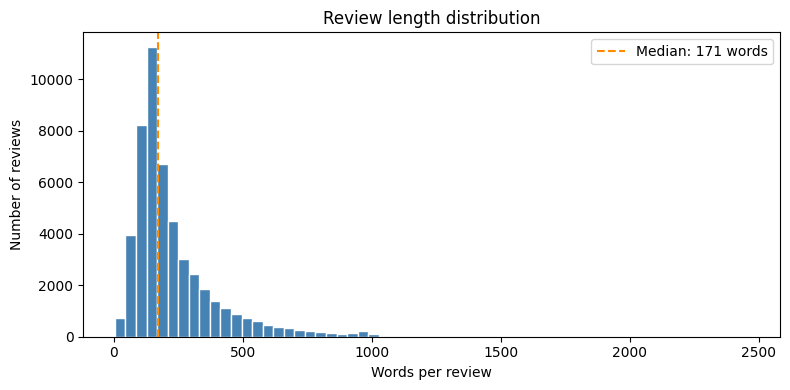

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["word_count"].dropna(), bins=60, color="steelblue", edgecolor="white")
ax.axvline(
    df["word_count"].median(), color="darkorange", linestyle="--",
    label=f"Median: {df['word_count'].median():.0f} words"
)
ax.set_title("Review length distribution")
ax.set_xlabel("Words per review")
ax.set_ylabel("Number of reviews")
ax.legend()
fig.tight_layout()
plt.show()



Dữ liệu gốc có 50.000 review, gồm 25.000 positive và 25.000 negative, nên cân bằng hoàn toàn trước khi làm sạch. Không có missing text hoặc missing label. Có 418 dòng trùng theo văn bản gốc; sau khi chuẩn hóa HTML, chữ thường và khoảng trắng, phát hiện tổng cộng 422 dòng trùng, tức thêm 4 dòng chỉ trùng sau chuẩn hóa. Không có text rỗng sau làm sạch và không có nhóm văn bản trùng mang nhãn xung đột. Giữ một bản cho mỗi cleaned text làm số mẫu modeling còn 49.578.

Độ dài trung bình là 228,87 từ, cao hơn median 171 từ; khoảng độ dài từ 4 đến 2.459 từ. Điều này phù hợp với phân phối lệch phải: nhiều review ngắn/trung bình và một số review rất dài kéo mean lên. Review dài có thể chứa nhiều chi tiết nội dung và ý kiến trái chiều, nên phép lấy trung bình embeddings có nguy cơ làm loãng một số tín hiệu sentiment; đây là giả thuyết về representation, không phải kết luận rằng mọi review dài đều bị dự đoán sai.

Sau làm sạch, positive chiếm khoảng 50,19% trong train/test và 50,18% trong validation. Chênh lệch rất nhỏ, không cho thấy class imbalance đáng kể. Vì vậy, không nên mặc định dùng class imbalance để giải thích các lỗi ở phần error analysis.

# Experiment 2 — Baseline

In [6]:
preprocessor = TextPreprocessor()
df = df.dropna(subset=["text", "label"]).copy()
df["text_clean"] = df["text"].apply(preprocessor.clean_text)

# Loại text rỗng và duplicate theo chính văn bản model nhận được.
empty_clean_texts = int(df["text_clean"].eq("").sum())
df = df.loc[df["text_clean"].ne("")].copy()
conflicting_texts = (
    df.groupby("text_clean")["label"].nunique().loc[lambda counts: counts > 1].index
)
conflicting_rows = int(df["text_clean"].isin(conflicting_texts).sum())
df = df.loc[~df["text_clean"].isin(conflicting_texts)].copy()
normalized_duplicates = int(df["text_clean"].duplicated().sum())
df = df.drop_duplicates(subset=["text_clean"]).reset_index(drop=True)

assert df["label"].isin(LABEL_ORDER).all()
assert df["text_clean"].is_unique
print("Empty cleaned texts removed:", empty_clean_texts)
print("Conflicting-label rows removed:", conflicting_rows)
print("Duplicate cleaned texts removed:", normalized_duplicates)
print("Number of samples for modeling:", len(df))
display(df[["text_clean", "label"]].head())

Empty cleaned texts removed: 0
Conflicting-label rows removed: 0
Duplicate cleaned texts removed: 422
Number of samples for modeling: 49578


,text_clean,label
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production. the filming tec...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there's a family where a little boy ...,negative
4,"petter mattei's ""love in the time of money"" is...",positive


label,negative,positive,Total,Positive (%)
Train,14817,14929,29746,50.19
Validation,4940,4976,9916,50.18
Test,4939,4977,9916,50.19


,Split A,Split B,Shared row indices,Shared cleaned texts
0,Train,Validation,0,0
1,Train,Test,0,0
2,Validation,Test,0,0


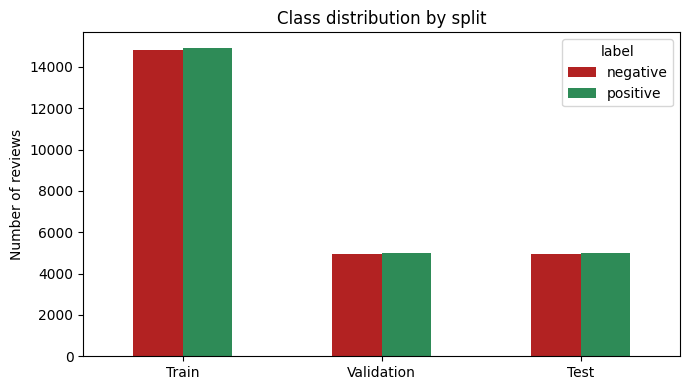

In [7]:
assert np.isclose(TRAIN_RATIO + VALID_RATIO + TEST_RATIO, 1.0)
assert all(ratio > 0 for ratio in (TRAIN_RATIO, VALID_RATIO, TEST_RATIO))
X = df["text_clean"]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=VALID_RATIO + TEST_RATIO,
    random_state=RANDOM_SEED,
    stratify=y
)
test_ratio_inside_temp = TEST_RATIO / (VALID_RATIO + TEST_RATIO)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp,
    test_size=test_ratio_inside_temp,
    random_state=RANDOM_SEED,
    stratify=y_temp
)

split_texts = {"Train": X_train, "Validation": X_valid, "Test": X_test}
split_labels = {"Train": y_train, "Validation": y_valid, "Test": y_test}
split_distribution = pd.DataFrame({
    name: labels.value_counts().reindex(LABEL_ORDER, fill_value=0)
    for name, labels in split_labels.items()
}).T
split_distribution["Total"] = split_distribution.sum(axis=1)
split_distribution["Positive (%)"] = (
    split_distribution["positive"] / split_distribution["Total"] * 100
).round(2)
display(split_distribution)

split_audit = pd.DataFrame([
    {
        "Split A": left, "Split B": right,
        "Shared row indices": len(set(split_texts[left].index) & set(split_texts[right].index)),
        "Shared cleaned texts": len(set(split_texts[left]) & set(split_texts[right]))
    }
    for left, right in [("Train", "Validation"), ("Train", "Test"), ("Validation", "Test")]
])
display(split_audit)
assert split_audit[["Shared row indices", "Shared cleaned texts"]].eq(0).all().all()

split_distribution[LABEL_ORDER].plot.bar(
    figsize=(7, 4), color=["firebrick", "seagreen"], rot=0
)
plt.title("Class distribution by split")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

## Nhận xét chia dữ liệu — Vì sao fit TF-IDF trước split là leakage?

Split được stratify với 29.746 train, 9.916 validation, 9.916 test, tương ứng gần 60%/20%/20%. Tỷ lệ nhãn gần như được giữ nguyên giữa ba tập. Bảng audit cho thấy cả ba cặp train–validation, train–test và validation–test đều có 0 shared row indices và **0 shared cleaned texts. Kiểm tra này loại được overlap theo văn bản chuẩn hóa; nó không phải kiểm tra tất cả các dạng near-duplicate.

TF-IDF học vocabulary và IDF từ corpus. Với dạng IDF mặc định của sklearn, `idf(t) = log((1 + N) / (1 + df(t))) + 1`, cả N và df(t) đều phụ thuộc dữ liệu được dùng để fit. Nếu fit trên toàn bộ dataset trước split, từ chỉ xuất hiện trong test có thể đi vào vocabulary và các review test đã ảnh hưởng đến IDF dùng để biểu diễn train. Đây là sử dụng thông tin của tập đánh giá trong quá trình xây dựng model, dù chưa dùng nhãn test.

Trong notebook, từng cấu hình được fit trên train và đánh giá trên validation để chọn tham số. Sau khi chốt cấu hình, model cuối được fit lại trên train + validation = 39.662 mẫu, rồi đánh giá trên test. Việc refit train + validation ở bước cuối phù hợp vì test vẫn được giữ riêng; không dùng test để chọn C, min_df hoặc stopword policy.

Các thao tác bỏ HTML, lowercase và chuẩn hóa khoảng trắng là xử lý không học tham số. Chúng khác với fit vocabulary/IDF hoặc Word2Vec. Các cell confusion matrix, báo cáo từng class và export sử dụng prediction đã lưu, nên không tạo thêm lượt dự đoán test.

In [8]:
def build_model(C, min_df):
    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=False,
                ngram_range=(1, 1),
                min_df=min_df
            )
        ),
        (
            "classifier",
            LogisticRegression(
                C=C,
                max_iter=1000,
                solver="liblinear",
                random_state=RANDOM_SEED
            )
        )
    ])


candidate_configs = [
    {"C": 0.1, "min_df": 1},
    {"C": 0.5, "min_df": 1},
    {"C": 1.0, "min_df": 1},
    {"C": 2.0, "min_df": 2},
    {"C": 10.0, "min_df": 2},
]

In [9]:
validation_results = []
for config in candidate_configs:
    model = build_model(C=config["C"], min_df=config["min_df"])
    timing = fit_pipeline_with_timing(model, X_train, y_train)
    y_valid_pred = model.predict(X_valid)
    metrics = compute_metrics(y_valid, y_valid_pred)
    validation_results.append({
        **config,
        "val_accuracy": metrics["Accuracy"],
        "val_precision": metrics["Precision"],
        "val_recall": metrics["Recall"],
        "val_f1": metrics["F1"],
        "val_macro_f1": metrics["Macro F1"],
        **timing
    })
validation_results = pd.DataFrame(validation_results).sort_values(
    by=["val_f1", "C", "min_df"], ascending=[False, True, True]
).reset_index(drop=True)
display(validation_results)

,C,min_df,val_accuracy,val_precision,val_recall,val_f1,val_macro_f1,Feature fit time (s),Classifier fit time (s),Training time (s)
0,2.0,2,0.897943,0.891700,0.906752,0.899163,0.897928,7.005072,2.245722,9.250794
1,10.0,2,0.895220,0.889879,0.902934,0.896359,0.895207,6.591938,3.847960,10.439898
2,1.0,1,0.892295,0.885252,0.902331,0.893710,0.892276,3.625081,0.950473,4.575554
3,0.5,1,0.886547,0.877771,0.899116,0.888315,0.886519,3.565961,0.723868,4.289828
4,0.1,1,0.860226,0.846258,0.881632,0.863583,0.860141,3.558385,0.489294,4.047679


In [10]:
best_config = validation_results.iloc[0]

best_C = float(best_config["C"])
best_min_df = int(best_config["min_df"])

print("Best C:", best_C)
print("Best min_df:", best_min_df)
print("Best validation F1:", best_config["val_f1"])

Best C: 2.0
Best min_df: 2
Best validation F1: 0.8991630131526505


In [11]:
X_train_final = pd.concat([X_train, X_valid], ignore_index=True)
y_train_final = pd.concat([y_train, y_valid], ignore_index=True)
final_model = build_model(C=best_C, min_df=best_min_df)
baseline_timing = fit_pipeline_with_timing(final_model, X_train_final, y_train_final)
final_training_time = baseline_timing["Training time (s)"]
print(f"Final training time: {final_training_time:.2f} seconds")
display(pd.DataFrame([baseline_timing]))

Final training time: 13.03 seconds


,Feature fit time (s),Classifier fit time (s),Training time (s)
0,9.88018,3.145429,13.02561


In [12]:
# Không chạy cell này trong quá trình chọn tham số
y_test_pred = final_model.predict(X_test)

print(classification_report(
    y_test,
    y_test_pred,
    digits=4
))

              precision    recall  f1-score   support

    negative     0.9172    0.9042    0.9107      4939
    positive     0.9063    0.9190    0.9126      4977

    accuracy                         0.9117      9916
   macro avg     0.9118    0.9116    0.9116      9916
weighted avg     0.9117    0.9117    0.9117      9916



In [13]:
final_tfidf = final_model.named_steps["tfidf"]
vocabulary_size = len(final_tfidf.vocabulary_)
final_results = pd.DataFrame([{
    "Model": "TF-IDF + Logistic Regression",
    **baseline_timing,
    "Vocabulary size": vocabulary_size,
    **compute_metrics(y_test, y_test_pred)
}])
display(final_results.round(4))

,Model,Feature fit time (s),Classifier fit time (s),Training time (s),Vocabulary size,Accuracy,Precision,Recall,F1,Macro F1,TN,FP,FN,TP
0,TF-IDF + Logistic Regression,9.8802,3.1454,13.0256,54445,0.9117,0.9063,0.919,0.9126,0.9116,4466,473,403,4574


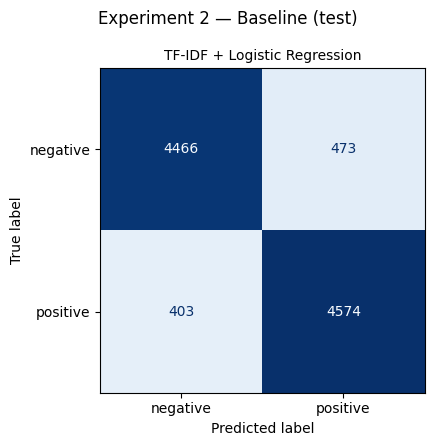

In [14]:
show_confusion_matrices(
    y_test,
    {"TF-IDF + Logistic Regression": y_test_pred},
    "Experiment 2 — Baseline (test)"
)


## Nhận xét Experiment 2 — Baseline

Cấu hình được chọn trên validation là C = 2,0, min_df = 2, với validation F1 0,899163. C = 10 có F1 0,896359, thấp hơn C = 2 trong lần chạy này; nới regularization không đảm bảo model tốt hơn. Tuy nhiên, đây chưa phải bằng chứng đủ để khẳng định C = 10 luôn overfit, vì chưa có learning curve hoặc kết quả nhiều split.

Model cuối có 54.445 feature, fit trong 13,0256 giây: TF-IDF 9,8802 giây và classifier 3,1454 giây. Trên test, accuracy 0,9117, precision 0,9063, recall 0,9190, F1 0,9126, Macro F1 0,9116. Baseline phân loại đúng 9.040/9.916 review, còn 876 lỗi. Trong khi đó, nếu luôn dự đoán positive trên test này, accuracy chỉ khoảng 50,19%, nên kết quả baseline không thể giải thích bằng việc chỉ chọn lớp đa số.

Confusion matrix là `[[4466, 473], [403, 4574]]` theo thứ tự negative, positive. Có 473 negative bị gán positive và 403 positive bị gán negative. Recall positive cao hơn precision positive: model tìm được phần lớn positive nhưng vẫn gán positive nhầm cho một số negative.

Test F1 cao hơn validation F1 khoảng 1,34 điểm phần trăm. Hai số này đến từ hai tập khác nhau và model cuối được fit trên 39.662 thay vì 29.746 mẫu; vì vậy, khác biệt không tự chứng minh leakage. Các kiểm tra split và code fit cũng không cho thấy việc dùng test để học feature hay chọn tham số.

# Experiment 3 — Representation comparison

In [15]:
def build_tfidf_lr(C, min_df=2, max_features=None, stop_words=None):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=False,
            ngram_range=(1, 1),
            min_df=min_df,
            max_features=max_features,
            stop_words=stop_words
        )),
        ("classifier", LogisticRegression(
            C=C, max_iter=1000, solver="liblinear", random_state=RANDOM_SEED
        ))
    ])


def build_tfidf_svm(C, min_df=2):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=False, ngram_range=(1, 1), min_df=min_df
        )),
        ("classifier", LinearSVC(
            C=C, max_iter=2000, random_state=RANDOM_SEED
        ))
    ])

In [16]:
tfidf_lr_configs = [
    {"C": 0.5, "min_df": 2},
    {"C": 1.0, "min_df": 2},
    {"C": 2.0, "min_df": 2},
    {"C": 10.0, "min_df": 2},
]

tfidf_lr_validation = []

for config in tfidf_lr_configs:
    model = build_tfidf_lr(
        C=config["C"],
        min_df=config["min_df"]
    )

    model.fit(X_train, y_train)
    y_valid_pred = model.predict(X_valid)

    metrics = compute_metrics(y_valid, y_valid_pred)

    tfidf_lr_validation.append({
        "C": config["C"],
        "min_df": config["min_df"],
        **metrics
    })

tfidf_lr_validation = pd.DataFrame(tfidf_lr_validation)
tfidf_lr_validation = tfidf_lr_validation.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

display(tfidf_lr_validation)

,C,min_df,Accuracy,Precision,Recall,F1,Macro F1,TN,FP,FN,TP
0,2.0,2,0.897943,0.891700,0.906752,0.899163,0.897928,4392,548,464,4512
1,10.0,2,0.895220,0.889879,0.902934,0.896359,0.895207,4384,556,483,4493
2,1.0,2,0.892800,0.885974,0.902532,0.894176,0.892781,4362,578,485,4491
3,0.5,2,0.886749,0.878264,0.898915,0.888470,0.886722,4320,620,503,4473


In [17]:
tfidf_svm_configs = [
    {"C": 0.1, "min_df": 2},
    {"C": 0.5, "min_df": 2},
    {"C": 1.0, "min_df": 2},
    {"C": 2.0, "min_df": 2},
]

tfidf_svm_validation = []

for config in tfidf_svm_configs:
    model = build_tfidf_svm(
        C=config["C"],
        min_df=config["min_df"]
    )

    model.fit(X_train, y_train)
    y_valid_pred = model.predict(X_valid)

    metrics = compute_metrics(y_valid, y_valid_pred)

    tfidf_svm_validation.append({
        "C": config["C"],
        "min_df": config["min_df"],
        **metrics
    })

tfidf_svm_validation = pd.DataFrame(tfidf_svm_validation)
tfidf_svm_validation = tfidf_svm_validation.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

display(tfidf_svm_validation)

,C,min_df,Accuracy,Precision,Recall,F1,Macro F1,TN,FP,FN,TP
0,0.5,2,0.898144,0.892673,0.905949,0.899262,0.898132,4398,542,468,4508
1,0.1,2,0.894716,0.886096,0.906752,0.896305,0.894691,4360,580,464,4512
2,1.0,2,0.893405,0.889640,0.899116,0.894353,0.893396,4385,555,502,4474
3,2.0,2,0.889472,0.887226,0.893288,0.890246,0.889466,4375,565,531,4445


In [18]:
w2v_preprocessor = TextPreprocessor()

train_tokens = [
    w2v_preprocessor.tokenize(text)
    for text in X_train
]

valid_tokens = [
    w2v_preprocessor.tokenize(text)
    for text in X_valid
]


def train_word2vec(tokenized_documents):
    return Word2Vec(
        sentences=tokenized_documents,
        vector_size=100,
        window=5,
        min_count=2,
        workers=4,
        sg=1,
        epochs=5,
        seed=RANDOM_SEED
    )


def average_word2vec(tokenized_documents, word2vec_model):
    vector_size = word2vec_model.vector_size

    document_vectors = np.zeros(
        (len(tokenized_documents), vector_size),
        dtype=np.float32
    )

    for i, tokens in enumerate(tokenized_documents):
        known_vectors = [
            word2vec_model.wv[token]
            for token in tokens
            if token in word2vec_model.wv
        ]

        if known_vectors:
            document_vectors[i] = np.mean(
                known_vectors,
                axis=0
            )

    return document_vectors

In [19]:
w2v_train_model = train_word2vec(train_tokens)

X_train_w2v = average_word2vec(
    train_tokens,
    w2v_train_model
)

X_valid_w2v = average_word2vec(
    valid_tokens,
    w2v_train_model
)

w2v_configs = [0.1, 0.5, 1.0, 2.0, 10.0]

w2v_validation = []

for C in w2v_configs:
    classifier = LogisticRegression(
        C=C,
        max_iter=1000,
        solver="lbfgs",
        random_state=RANDOM_SEED
    )

    classifier.fit(X_train_w2v, y_train)

    y_valid_pred = classifier.predict(X_valid_w2v)

    metrics = compute_metrics(y_valid, y_valid_pred)

    w2v_validation.append({
        "C": C,
        **metrics
    })

w2v_validation = pd.DataFrame(w2v_validation)
w2v_validation = w2v_validation.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

display(w2v_validation)

,C,Accuracy,Precision,Recall,F1,Macro F1,TN,FP,FN,TP
0,10.0,0.864764,0.862413,0.869172,0.865779,0.864756,4250,690,651,4325
1,2.0,0.863957,0.860322,0.870177,0.865221,0.863945,4237,703,646,4330
2,1.0,0.861940,0.859478,0.866559,0.863004,0.861932,4235,705,664,4312
3,0.5,0.859520,0.857371,0.863746,0.860547,0.859512,4225,715,678,4298
4,0.1,0.845805,0.842712,0.851688,0.847176,0.845792,4149,791,738,4238


## Word2Vec — Vocabulary coverage

Tỷ lệ token có vector và số review nhận vector 0 giúp kiểm tra chất lượng đầu vào của classifier. Dùng Word2Vec đã fit trên train; validation chỉ được transform.

In [20]:
def word2vec_coverage(tokens_by_review, word2vec_model):
    token_counts = np.array([len(tokens) for tokens in tokens_by_review])
    known_counts = np.array([
        sum(token in word2vec_model.wv for token in tokens)
        for tokens in tokens_by_review
    ])
    fractions = np.divide(
        known_counts, token_counts,
        out=np.zeros(len(token_counts), dtype=float),
        where=token_counts > 0
    )
    return {
        "Mean known-token fraction": float(fractions.mean()),
        "Overall known-token fraction": float(
            known_counts.sum() / token_counts.sum()
        ) if token_counts.sum() else 0.0,
        "Reviews with no known tokens": int((known_counts == 0).sum())
    }

word2vec_coverage_results = pd.DataFrame([
    {
        "Split": split,
        **word2vec_coverage(tokens, w2v_train_model),
        "Zero-vector reviews": int(np.all(vectors == 0, axis=1).sum())
    }
    for split, tokens, vectors in [
        ("Train", train_tokens, X_train_w2v),
        ("Validation", valid_tokens, X_valid_w2v)
    ]
])
display(word2vec_coverage_results.round(4))
print("Embedding dimension:", w2v_train_model.vector_size)
print("Vocabulary size:", len(w2v_train_model.wv))

,Split,Mean known-token fraction,Overall known-token fraction,Reviews with no known tokens,Zero-vector reviews
0,Train,0.9949,0.9949,0,0
1,Validation,0.9910,0.9904,0,0


Embedding dimension: 100
Vocabulary size: 54650


## Nhận xét về Word2Vec coverage

Word2Vec fit trên train có 54.650 từ trong vocabulary và mỗi từ được biểu diễn bằng vector 100 chiều. Tỷ lệ token có vector trung bình trên mỗi review đạt 99,49% ở train và 99,10% ở validation; tỷ lệ tính trên toàn bộ token validation là 99,04%. Cả hai tập đều có 0 review không có từ known và 0 zero-vector review.

Như vậy, chất lượng thấp hơn của Average Word2Vec không thể giải thích đơn giản bằng việc phần lớn review bị biến thành vector 0 hoặc mất hầu hết từ. Coverage cao chỉ xác nhận phần lớn token có vector, chưa xác nhận vector phù hợp để phân biệt sentiment. Một từ sentiment quan trọng vẫn có thể bị làm loãng khi lấy trung bình với nhiều từ trung tính; embeddings học từ context cũng không trực tiếp được tối ưu theo nhãn positive/negative.

Cần phân biệt vocabulary size với feature count của classifier: vocabulary chứa nhiều chục nghìn từ, nhưng sau averaging, mỗi review vẫn chỉ có 100 feature. Sau refit trên train + validation, vocabulary của Word2Vec tăng lên 61.649 từ.

In [21]:
best_lr_row = tfidf_lr_validation.iloc[0]
best_svm_row = tfidf_svm_validation.iloc[0]
best_w2v_row = w2v_validation.iloc[0]

best_lr_C = float(best_lr_row["C"])
best_lr_min_df = int(best_lr_row["min_df"])

best_svm_C = float(best_svm_row["C"])
best_svm_min_df = int(best_svm_row["min_df"])

best_w2v_C = float(best_w2v_row["C"])

print("Best TF-IDF + LR C:", best_lr_C)
print("Best TF-IDF + SVM C:", best_svm_C)
print("Best Word2Vec + LR C:", best_w2v_C)

Best TF-IDF + LR C: 2.0
Best TF-IDF + SVM C: 0.5
Best Word2Vec + LR C: 10.0


## Bổ sung — Vocabulary và stopwords (validation)

Thử 5k, 10k, 20k feature và một cấu hình 10k bỏ English stopwords. Giữ C, min_df, unigram và classifier cố định để so sánh từng thay đổi. Chỉ fit train và đánh giá validation; các model này không dùng test và không thay thế cấu hình các experiment đã chốt. English stopwords có thể chứa các từ phủ định như "not" và "no".

,Model,Representation,Classifier,Features,C,min_df,Max features,Stopwords,Vocabulary size,Feature count,...,Training time (s),Accuracy,Precision,Recall,F1,Macro F1,TN,FP,FN,TP
0,5k — keep stopwords,TF-IDF,Logistic Regression,Unigram,2.0,2,5000,Kept,5000,5000,...,5.8024,0.8908,0.8878,0.8955,0.8916,0.8908,4377,563,520,4456
1,10k — keep stopwords,TF-IDF,Logistic Regression,Unigram,2.0,2,10000,Kept,10000,10000,...,7.1217,0.8959,0.8900,0.9043,0.8971,0.8959,4384,556,476,4500
2,20k — keep stopwords,TF-IDF,Logistic Regression,Unigram,2.0,2,20000,Kept,20000,20000,...,7.6454,0.8986,0.8925,0.9074,0.8999,0.8986,4396,544,461,4515
3,10k — remove stopwords,TF-IDF,Logistic Regression,Unigram,2.0,2,10000,Removed,10000,10000,...,6.1534,0.8915,0.8842,0.9019,0.8930,0.8915,4352,588,488,4488


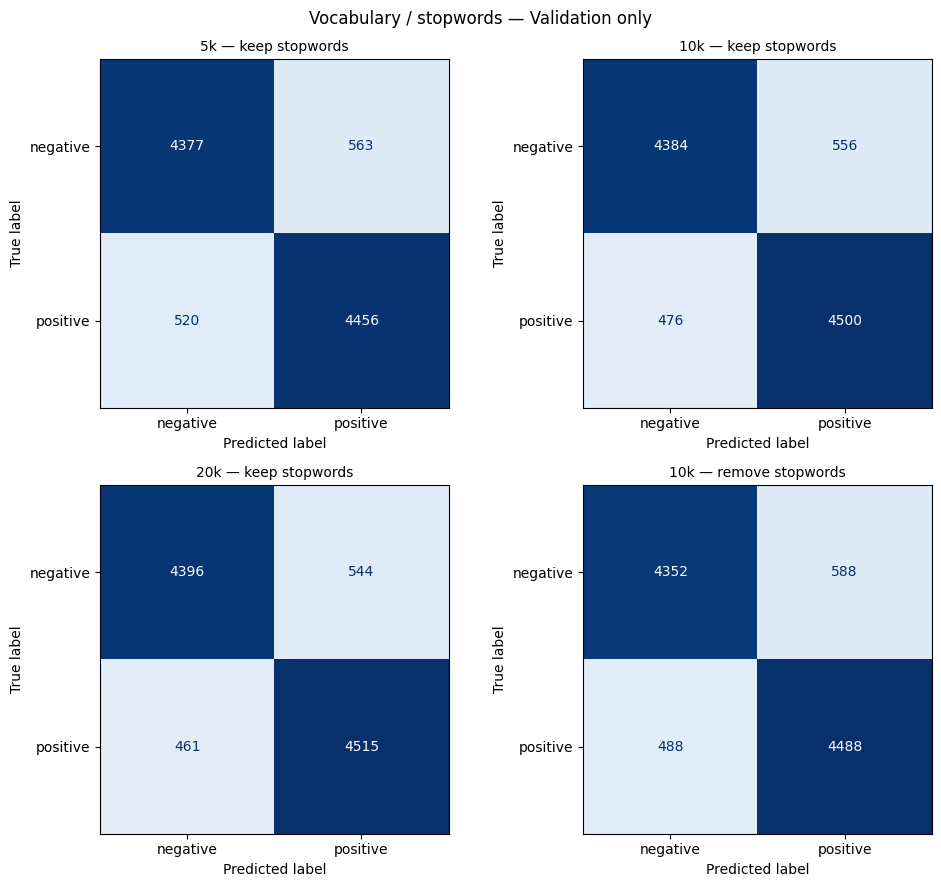

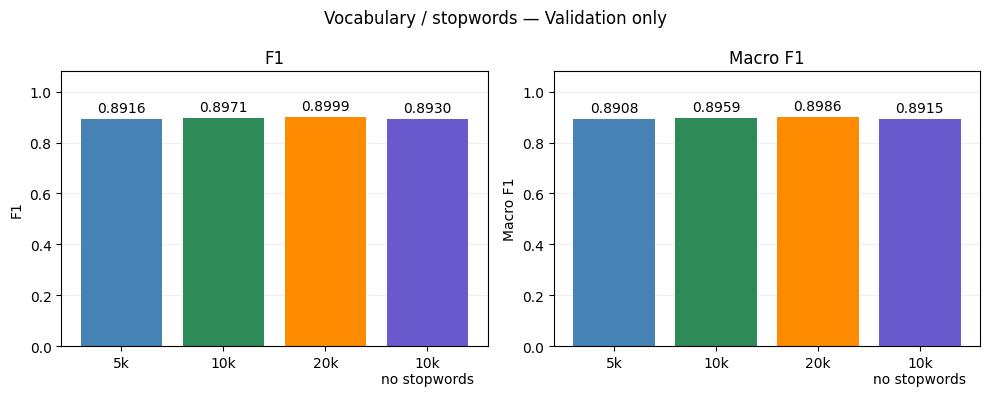

In [22]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

ablation_configs = [
    {"name": "5k — keep stopwords", "max_features": 5000, "remove_stopwords": False},
    {"name": "10k — keep stopwords", "max_features": 10000, "remove_stopwords": False},
    {"name": "20k — keep stopwords", "max_features": 20000, "remove_stopwords": False},
    {"name": "10k — remove stopwords", "max_features": 10000, "remove_stopwords": True}
]
ablation_rows = []
ablation_predictions = {}
for config in ablation_configs:
    stop_words = sorted(ENGLISH_STOP_WORDS) if config["remove_stopwords"] else None
    model = build_tfidf_lr(
        C=best_lr_C, min_df=best_lr_min_df,
        max_features=config["max_features"], stop_words=stop_words
    )
    timing = fit_pipeline_with_timing(model, X_train, y_train)
    predictions = model.predict(X_valid)
    ablation_predictions[config["name"]] = predictions
    vocabulary = model.named_steps["tfidf"].vocabulary_
    ablation_rows.append({
        "Model": config["name"],
        "Representation": "TF-IDF",
        "Classifier": "Logistic Regression",
        "Features": "Unigram",
        "C": best_lr_C,
        "min_df": best_lr_min_df,
        "Max features": config["max_features"],
        "Stopwords": "Removed" if config["remove_stopwords"] else "Kept",
        "Vocabulary size": len(vocabulary),
        "Feature count": len(vocabulary),
        "'not' in vocabulary": "not" in vocabulary,
        **timing,
        **compute_metrics(y_valid, predictions)
    })
ablation_results = pd.DataFrame(ablation_rows)
display(ablation_results.round(4))

show_confusion_matrices(
    y_valid, ablation_predictions, "Vocabulary / stopwords — Validation only"
)
show_result_comparison(
    ablation_results,
    ["5k", "10k", "20k", "10k\nno stopwords"],
    "Vocabulary / stopwords — Validation only",
    metrics=("F1", "Macro F1")
)

## Nhận xét ablation — Vocabulary size và stopwords

Các cấu hình này dùng cùng train/validation, cùng C = 2, min_df = 2, cùng unigram và Logistic Regression. Vì vậy, có thể đối chiếu ảnh hưởng của giới hạn vocabulary và stopword policy trong điều kiện này.

| Cấu hình | Validation accuracy | Validation F1 | Training time (s) |
|---|---:|---:|---:|
| 5k, giữ stopwords | 0,8908 | 0,8916 | 5,8024 |
| 10k, giữ stopwords | 0,8959 | 0,8971 | 7,1217 |
| 20k, giữ stopwords | 0,8986 | 0,8999 | 7,6454 |
| 10k, bỏ stopwords | 0,8915 | 0,8930 | 6,1534 |

Vocabulary lớn hơn có chắc chắn tăng accuracy không? Trong phạm vi 5k → 10k → 20k, cả accuracy và F1 đều tăng; nhiều từ hữu ích hơn có thể được giữ lại. Tuy nhiên, cấu hình không giới hạn vocabulary ở phần tuning có validation F1 0,899163, hơi thấp hơn 20k (0,899851, tính từ confusion matrix). Vì vậy, lần chạy này không cho thấy performance tăng đơn điệu khi tiếp tục tăng vocabulary. Chênh lệch khoảng 0,07 điểm phần trăm giữa hai F1 rất nhỏ, chưa đủ để khẳng định lợi thế ổn định.

Bỏ stopwords có chắc chắn giúp không? Khi giữ cap 10k, bỏ stopwords làm F1 giảm khoảng 0,0042, accuracy giảm khoảng 0,0044. FP tăng 556 → 588, FN tăng 476 → 488, tức thêm 44 lỗi validation. Thời gian fit giảm khoảng 0,97 giây, nhưng không bù được việc metrics giảm nếu mục tiêu là chất lượng phân loại.

Bảng vocabulary xác nhận `not` có trong model giữ stopwords nhưng mất ở model bỏ stopwords. Điều này hỗ trợ giả thuyết rằng loại một số từ phủ định làm mất tín hiệu sentiment. Tuy nhiên, ablation loại cả danh sách stopwords và thay đổi các từ được chọn vào cap 10k, nên chưa thể quy toàn bộ 44 lỗi tăng thêm chỉ cho từ `not`. Các kết quả này chỉ dùng validation, không lấy test để đổi cấu hình cuối.

In [23]:
# Chốt cấu hình trên validation trước khi fit lại train + validation.
X_train_final = pd.concat([X_train, X_valid], ignore_index=True)
y_train_final = pd.concat([y_train, y_valid], ignore_index=True)
final_models = {}
training_times = {}
training_breakdown = {}

tfidf_lr_final = build_tfidf_lr(C=best_lr_C, min_df=best_lr_min_df)
training_breakdown["TF-IDF + Logistic Regression"] = fit_pipeline_with_timing(
    tfidf_lr_final, X_train_final, y_train_final
)
tfidf_svm_final = build_tfidf_svm(C=best_svm_C, min_df=best_svm_min_df)
training_breakdown["TF-IDF + Linear SVM"] = fit_pipeline_with_timing(
    tfidf_svm_final, X_train_final, y_train_final
)
for name, model in [
    ("TF-IDF + Logistic Regression", tfidf_lr_final),
    ("TF-IDF + Linear SVM", tfidf_svm_final)
]:
    final_models[name] = model
    training_times[name] = training_breakdown[name]["Training time (s)"]

In [24]:
train_final_tokens = [
    w2v_preprocessor.tokenize(text) for text in X_train_final
]
w2v_final_tokens_for_test = [
    w2v_preprocessor.tokenize(text) for text in X_test
]

start = time.perf_counter()
w2v_final_model = train_word2vec(train_final_tokens)
X_train_final_w2v = average_word2vec(train_final_tokens, w2v_final_model)
w2v_feature_time = time.perf_counter() - start

w2v_lr_final = LogisticRegression(
    C=best_w2v_C, max_iter=1000, solver="lbfgs", random_state=RANDOM_SEED
)
start = time.perf_counter()
w2v_lr_final.fit(X_train_final_w2v, y_train_final)
w2v_classifier_time = time.perf_counter() - start

w2v_name = "Average Word2Vec + Logistic Regression"
training_breakdown[w2v_name] = {
    "Feature fit time (s)": w2v_feature_time,
    "Classifier fit time (s)": w2v_classifier_time,
    "Training time (s)": w2v_feature_time + w2v_classifier_time
}
training_times[w2v_name] = training_breakdown[w2v_name]["Training time (s)"]
final_models[w2v_name] = w2v_lr_final

In [25]:
# Chỉ chạy một lần cho mỗi model cuối cùng

y_test_predictions = {}

y_test_predictions[
    "TF-IDF + Logistic Regression"
] = tfidf_lr_final.predict(X_test)

y_test_predictions[
    "TF-IDF + Linear SVM"
] = tfidf_svm_final.predict(X_test)

X_test_w2v = average_word2vec(
    w2v_final_tokens_for_test,
    w2v_final_model
)

y_test_predictions[
    "Average Word2Vec + Logistic Regression"
] = w2v_lr_final.predict(X_test_w2v)

In [26]:
experiment_3_results = []
for model_name, predictions in y_test_predictions.items():
    is_tfidf = "TF-IDF" in model_name
    model = final_models[model_name]
    vocab_size = (
        len(model.named_steps["tfidf"].vocabulary_)
        if is_tfidf else len(w2v_final_model.wv)
    )
    experiment_3_results.append({
        "Model": model_name,
        "Representation": "TF-IDF" if is_tfidf else "Average Word2Vec",
        "Classifier": "Linear SVM" if "SVM" in model_name else "Logistic Regression",
        "Vocabulary size": vocab_size,
        "Feature count": vocab_size if is_tfidf else w2v_final_model.vector_size,
        **training_breakdown[model_name],
        **compute_metrics(y_test, predictions)
    })
experiment_3_results = pd.DataFrame(experiment_3_results)
display(experiment_3_results.round(4))

,Model,Representation,Classifier,Vocabulary size,Feature count,Feature fit time (s),Classifier fit time (s),Training time (s),Accuracy,Precision,Recall,F1,Macro F1,TN,FP,FN,TP
0,TF-IDF + Logistic Regression,TF-IDF,Logistic Regression,54445,54445,7.3307,1.5548,8.8855,0.9117,0.9063,0.9190,0.9126,0.9116,4466,473,403,4574
1,TF-IDF + Linear SVM,TF-IDF,Linear SVM,54445,54445,11.5374,0.6812,12.2186,0.9125,0.9080,0.9186,0.9133,0.9125,4476,463,405,4572
2,Average Word2Vec + Logistic Regression,Average Word2Vec,Logistic Regression,61649,100,178.1074,0.4365,178.5439,0.8812,0.8801,0.8837,0.8819,0.8812,4340,599,579,4398


In [27]:
# Báo cáo từng class từ prediction đã lưu; không predict test thêm.
for model_name, predictions in y_test_predictions.items():
    print(f"\n{model_name}")
    print(classification_report(
        y_test, predictions, labels=LABEL_ORDER,
        digits=4, zero_division=0
    ))


TF-IDF + Logistic Regression
              precision    recall  f1-score   support

    negative     0.9172    0.9042    0.9107      4939
    positive     0.9063    0.9190    0.9126      4977

    accuracy                         0.9117      9916
   macro avg     0.9118    0.9116    0.9116      9916
weighted avg     0.9117    0.9117    0.9117      9916


TF-IDF + Linear SVM
              precision    recall  f1-score   support

    negative     0.9170    0.9063    0.9116      4939
    positive     0.9080    0.9186    0.9133      4977

    accuracy                         0.9125      9916
   macro avg     0.9125    0.9124    0.9125      9916
weighted avg     0.9125    0.9125    0.9125      9916


Average Word2Vec + Logistic Regression
              precision    recall  f1-score   support

    negative     0.8823    0.8787    0.8805      4939
    positive     0.8801    0.8837    0.8819      4977

    accuracy                         0.8812      9916
   macro avg     0.8812    0.8812    

## Model comparison — Test results

Confusion matrix cho từng model và biểu đồ F1, thời gian huấn luyện. Các hình sử dụng kết quả đã tính, không chạy dự đoán test lại.


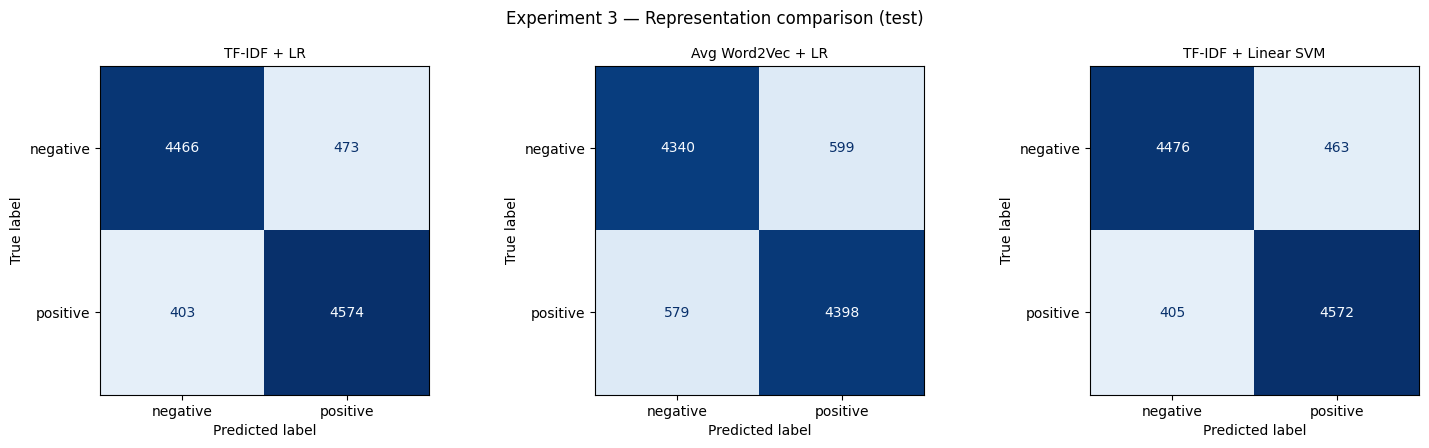

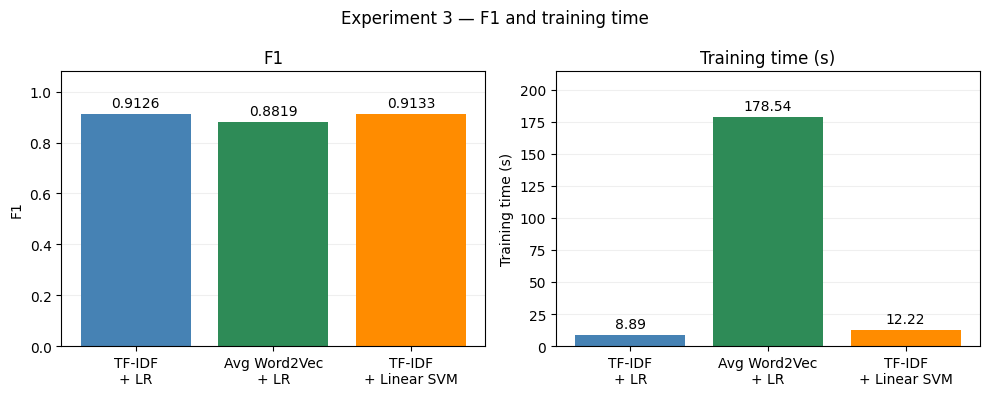

In [28]:
show_confusion_matrices(
    y_test,
    {
        "TF-IDF + LR": y_test_predictions["TF-IDF + Logistic Regression"],
        "Avg Word2Vec + LR": y_test_predictions["Average Word2Vec + Logistic Regression"],
        "TF-IDF + Linear SVM": y_test_predictions["TF-IDF + Linear SVM"]
    },
    "Experiment 3 — Representation comparison (test)"
)

comparison_table = experiment_3_results.set_index(["Representation", "Classifier"]).loc[
    [
        ("TF-IDF", "Logistic Regression"),
        ("Average Word2Vec", "Logistic Regression"),
        ("TF-IDF", "Linear SVM")
    ]
].reset_index()
show_result_comparison(
    comparison_table,
    ["TF-IDF\n+ LR", "Avg Word2Vec\n+ LR", "TF-IDF\n+ Linear SVM"],
    "Experiment 3 — F1 and training time"
)


## Nhận xét Experiment 3 — Vì sao representation tạo kết quả khác nhau?

| Pipeline | Test accuracy | Test F1 | Macro F1 | Training time (s) |
|---|---:|---:|---:|---:|
| TF-IDF + Logistic Regression | 0,9117 | 0,9126 | 0,9116 | 8,8855 |
| Average Word2Vec + Logistic Regression | 0,8812 | 0,8819 | 0,8812 | 178,5439 |
| TF-IDF + Linear SVM | 0,9125 | 0,9133 | 0,9125 | 12,2186 |

TF-IDF + LR cao hơn Average Word2Vec + LR khoảng 3,07 điểm phần trăm F1 và dự đoán đúng thêm 302 review trên cùng test. TF-IDF giữ riêng 54.445 lexical feature, nên các từ sentiment như `great`, `excellent`, `worst`, `boring` có thể được classifier gán trọng số riêng. Với Average Word2Vec, tất cả từ được tổng hợp thành một vector 100 chiều. Sự hiện diện của một từ quyết định sentiment có thể bị pha loãng; thông tin về thứ tự từ và quan hệ giữa `not` với từ sau nó không được biểu diễn trực tiếp.

Coverage validation đã trên 99% và không có zero-vector review, nên OOV không phải lời giải thích duy nhất cho khoảng cách. Chất lượng embeddings học từ corpus, phép averaging và tín hiệu lexical của task đều là các yếu tố cần xét. Hai model cũng có C và solver khác nhau: TF-IDF dùng C = 2, liblinear, Word2Vec dùng C = 10, lbfgs. Vì vậy, đây là so sánh các pipeline đã tuning trên validation, chưa phải phép thử chỉ thay representation và giữ mọi tham số khác hoàn toàn giống nhau.

Average Word2Vec mất 178,1074 giây cho representation, chiếm khoảng 99,76% tổng thời gian 178,5439 giây. Fit LR trên vector 100 chiều chỉ mất 0,4365 giây, nhanh hơn phần classifier TF-IDF 1,5548 giây, nhưng tổng pipeline Word2Vec vẫn lâu hơn khoảng **20,09 lần** trong phép đo này. Ít chiều không đồng nghĩa toàn bộ quá trình huấn luyện nhanh hơn khi phải học embeddings từ đầu.

SVM đúng thêm 8 review so với TF-IDF + LR: FP giảm 473 → 463 nhưng FN tăng 403 → 405. F1 chỉ tăng khoảng 0,0007. SVM có điểm số nhỉnh hơn ở split này, nhưng khác biệt nhỏ và chưa có kiểm định hoặc nhiều seed để khẳng định ưu thế ổn định.

TF-IDF + LR ở Experiment 2, Experiment 3 và unigram ở Experiment 5 có cùng tham số, dữ liệu fit và confusion matrix. Việc metrics giống nhau là hợp lý. Thời gian 13,0256 / 8,8855 / 12,1601 giây là ba lượt đo riêng và có thể chịu ảnh hưởng của cache, tải CPU hoặc trạng thái máy; không xem sự chênh lệch đó là thay đổi chất lượng model.

# Experiment 4 — Word order

In [29]:
sentences = {
    "S1": "this movie is good",
    "S2": "this movie is not good",
    "S3": "good is movie this"
}

experiment4_preprocessor = TextPreprocessor()

tokenized_sentences = {
    name: experiment4_preprocessor.tokenize(text)
    for name, text in sentences.items()
}

tokenized_sentences

{'S1': ['this', 'movie', 'is', 'good'],
 'S2': ['this', 'movie', 'is', 'not', 'good'],
 'S3': ['good', 'is', 'movie', 'this']}

In [30]:
sentence_vectors = {}

for name, tokens in tokenized_sentences.items():
    sentence_vectors[name] = average_word2vec(
        [tokens],
        w2v_final_model
    )[0]

sentence_vectors = np.vstack([
    sentence_vectors["S1"],
    sentence_vectors["S2"],
    sentence_vectors["S3"]
])

print("Vector shape:", sentence_vectors.shape)

Vector shape: (3, 100)


In [31]:
similarity_matrix = cosine_similarity(sentence_vectors)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=["S1", "S2", "S3"],
    columns=["S1", "S2", "S3"]
)

display(similarity_df)

,S1,S2,S3
S1,1.000000,0.980951,1.000000
S2,0.980951,1.000000,0.980951
S3,1.000000,0.980951,1.000000


In [32]:
difference_s1_s3 = np.linalg.norm(
    sentence_vectors[0] - sentence_vectors[2]
)

print("Distance between S1 and S3:", difference_s1_s3)

Distance between S1 and S3: 1.07554655e-07


In [33]:
w2v_predictions = w2v_lr_final.predict(sentence_vectors)
w2v_probabilities = w2v_lr_final.predict_proba(sentence_vectors)
w2v_classes = list(w2v_lr_final.classes_)
experiment4_results = pd.DataFrame({
    "Sentence ID": list(sentences),
    "Sentence": list(sentences.values()),
    "Prediction": w2v_predictions,
    "Negative probability": w2v_probabilities[:, w2v_classes.index("negative")],
    "Positive probability": w2v_probabilities[:, w2v_classes.index("positive")]
})
display(experiment4_results)

,Sentence ID,Sentence,Prediction,Negative probability,Positive probability
0,S1,this movie is good,positive,0.026694,0.973306
1,S2,this movie is not good,negative,0.535769,0.464231
2,S3,good is movie this,positive,0.026694,0.973306


In [34]:
cleaned_sentences = [
    experiment4_preprocessor.clean_text(text) for text in sentences.values()
]
tfidf_predictions = tfidf_lr_final.predict(cleaned_sentences)
tfidf_probabilities = tfidf_lr_final.predict_proba(cleaned_sentences)
tfidf_classes = list(tfidf_lr_final.named_steps["classifier"].classes_)
experiment4_results["TF-IDF prediction"] = tfidf_predictions
experiment4_results["TF-IDF positive probability"] = (
    tfidf_probabilities[:, tfidf_classes.index("positive")]
)
display(experiment4_results)

tfidf_probe_vectors = tfidf_lr_final.named_steps["tfidf"].transform(cleaned_sentences)
word_order_checks = pd.DataFrame([
    {
        "Representation": "Average Word2Vec",
        "S1-S3 vector distance": float(difference_s1_s3),
        "S1-S3 vectors equal": bool(np.allclose(
            sentence_vectors[0], sentence_vectors[2], atol=1e-6
        ))
    },
    {
        "Representation": "TF-IDF unigram",
        "S1-S3 vector distance": float(np.linalg.norm(
            (tfidf_probe_vectors[0] - tfidf_probe_vectors[2]).data
        )),
        "S1-S3 vectors equal": bool(np.allclose(
            (tfidf_probe_vectors[0] - tfidf_probe_vectors[2]).data, 0
        ))
    }
])
display(word_order_checks)

,Sentence ID,Sentence,Prediction,Negative probability,Positive probability,TF-IDF prediction,TF-IDF positive probability
0,S1,this movie is good,positive,0.026694,0.973306,positive,0.907535
1,S2,this movie is not good,negative,0.535769,0.464231,positive,0.590660
2,S3,good is movie this,positive,0.026694,0.973306,positive,0.907535


,Representation,S1-S3 vector distance,S1-S3 vectors equal
0,Average Word2Vec,1.075547e-07,True
1,TF-IDF unigram,0.000000e+00,True


## Word order — Similarity and prediction probabilities

Heatmap hiển thị cosine similarity của S1, S2, S3. Biểu đồ bên cạnh hiển thị xác suất positive của Average Word2Vec + LR. Đây là các câu minh họa chưa được gán nhãn đúng, nên không tính confusion matrix.


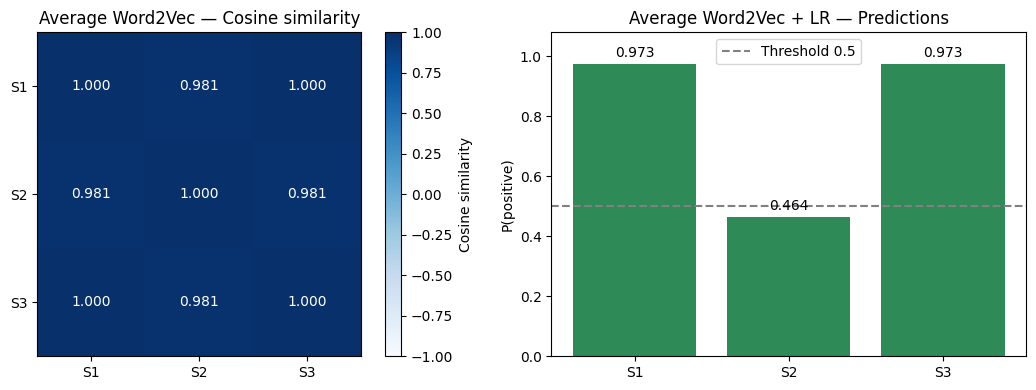

S1: this movie is good
S2: this movie is not good
S3: good is movie this


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
heatmap = axes[0].imshow(similarity_df.to_numpy(), cmap="Blues", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(similarity_df.columns)), similarity_df.columns)
axes[0].set_yticks(range(len(similarity_df.index)), similarity_df.index)
axes[0].set_title("Average Word2Vec — Cosine similarity")
for i in range(len(similarity_df)):
    for j in range(len(similarity_df.columns)):
        value = similarity_df.iloc[i, j]
        axes[0].text(
            j, i, f"{value:.3f}", ha="center", va="center",
            color="white" if value > 0.5 else "black"
        )
fig.colorbar(heatmap, ax=axes[0], label="Cosine similarity")

bars = axes[1].bar(
    list(sentences), experiment4_results["Positive probability"], color="seagreen"
)
axes[1].axhline(0.5, color="gray", linestyle="--", label="Threshold 0.5")
axes[1].set_ylim(0, 1.08)
axes[1].set_ylabel("P(positive)")
axes[1].set_title("Average Word2Vec + LR — Predictions")
axes[1].bar_label(bars, fmt="%.3f", padding=3)
axes[1].legend()
fig.tight_layout()
plt.show()

for sentence_id, sentence in sentences.items():
    print(f"{sentence_id}: {sentence}")


## Nhận xét Experiment 4 — Representation có hiểu vai trò của “not” không?

| Câu | Average Word2Vec P(positive) | Word2Vec prediction | TF-IDF P(positive) | TF-IDF prediction |
|---|---:|---|---:|---|
| S1: this movie is good | 0,973306 | positive | 0,907535 | positive |
| S2: this movie is not good | 0,464231 | negative | 0,590660 | positive |
| S3: good is movie this | 0,973306 | positive | 0,907535 | positive |

Thay đổi thứ tự từ: S1 và S3 có cùng các từ nhưng khác thứ tự. Distance của hai vector Average Word2Vec chỉ 1,0755 × 10⁻⁷, được xem là bằng nhau trong sai số số học; TF-IDF unigram có distance 0. Hai model cũng cho cùng xác suất và prediction ở S1/S3. Đây là bằng chứng trực tiếp rằng các representation này không biểu diễn thứ tự từ: phép cộng/trung bình vector có tính giao hoán, còn unigram chỉ ghi nhận từng term.

Thêm từ phủ định: S1/S2 có cosine similarity*0,980951, nhưng Average Word2Vec vẫn đổi prediction positive → negative vì P(positive) giảm 0,973306 → 0,464231 và đi qua threshold 0,5. Cosine cao không ngăn classifier đặt hai vector ở hai phía decision boundary. Vì vậy, không thể viết rằng Average Word2Vec hoàn toàn không nhận ra `not` trong lần chạy này.

Tuy nhiên, model mới phản ứng với việc thêm vector của `not`; chưa có bằng chứng rằng nó hiểu scope của phủ định, cấu trúc câu hay các cách diễn đạt khác. Một probe đúng không chứng minh đã giải quyết mọi câu phủ định. P(negative) của S2 chỉ 0,535769, tương đối gần threshold.

TF-IDF unigram cũng bị ảnh hưởng bởi `not`: P(positive) giảm 0,907535 → 0,590660, nhưng vẫn trên 0,5 nên dự đoán positive, không phù hợp với ý nghĩa thông thường của “not good”. Unigram có feature cho từng từ nhưng không có feature riêng cho quan hệ `not good`. Đây là động cơ thử bigram ở experiment tiếp theo, không phải bằng chứng rằng embeddings luôn kém hơn TF-IDF về phủ định.

Các câu này là minh họa định tính; chưa dùng chúng để tính accuracy/F1 hoặc chọn lại tham số model.

# Experiment 5 — n-gram features

In [36]:
# Nếu đã có từ Experiment 2 thì có thể bỏ qua cell này

X_train_final = pd.concat(
    [X_train, X_valid],
    ignore_index=True
)

y_train_final = pd.concat(
    [y_train, y_valid],
    ignore_index=True
)

# Dùng C đã chọn trên validation cho TF-IDF + Logistic Regression ở Experiment 3.
# Giữ C cố định để Experiment 5 chỉ so sánh unigram với unigram + bigram.
EXPERIMENT_C = best_lr_C
MIN_DF = 2

In [37]:
def build_ngram_model(ngram_range):
    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=False,
                ngram_range=ngram_range,
                min_df=MIN_DF
            )
        ),
        (
            "classifier",
            LogisticRegression(
                C=EXPERIMENT_C,
                max_iter=1000,
                solver="liblinear",
                random_state=RANDOM_SEED
            )
        )
    ])


unigram_model = build_ngram_model(
    ngram_range=(1, 1)
)

bigram_model = build_ngram_model(
    ngram_range=(1, 2)
)

In [38]:
unigram_timing = fit_pipeline_with_timing(unigram_model, X_train_final, y_train_final)
bigram_timing = fit_pipeline_with_timing(bigram_model, X_train_final, y_train_final)
unigram_training_time = unigram_timing["Training time (s)"]
bigram_training_time = bigram_timing["Training time (s)"]
print(f"Unigram training time: {unigram_training_time:.2f} seconds")
print(f"Uni + Bigram training time: {bigram_training_time:.2f} seconds")

Unigram training time: 12.16 seconds
Uni + Bigram training time: 35.30 seconds


In [39]:
unigram_vocab_size = len(
    unigram_model.named_steps["tfidf"].vocabulary_
)

bigram_vocab_size = len(
    bigram_model.named_steps["tfidf"].vocabulary_
)

print("Unigram vocabulary:", unigram_vocab_size)
print("Uni + Bigram vocabulary:", bigram_vocab_size)

Unigram vocabulary: 54445
Uni + Bigram vocabulary: 613024


In [40]:
y_test_pred_unigram = unigram_model.predict(X_test)

y_test_pred_bigram = bigram_model.predict(X_test)

In [41]:
unigram_metrics = compute_metrics(y_test, y_test_pred_unigram)
bigram_metrics = compute_metrics(y_test, y_test_pred_bigram)
unigram_f1 = unigram_metrics["F1"]
bigram_f1 = bigram_metrics["F1"]
ngram_results = pd.DataFrame([
    {
        "Features": "Unigram", "Vocabulary": unigram_vocab_size,
        **unigram_timing, **unigram_metrics
    },
    {
        "Features": "Uni + Bigram", "Vocabulary": bigram_vocab_size,
        **bigram_timing, **bigram_metrics
    }
])
display(ngram_results.round(4))
print("Bigram features present:")
for phrase in ["not good", "very good"]:
    print(f"  {phrase}: {phrase in bigram_model.named_steps['tfidf'].vocabulary_}")

,Features,Vocabulary,Feature fit time (s),Classifier fit time (s),Training time (s),Accuracy,Precision,Recall,F1,Macro F1,TN,FP,FN,TP
0,Unigram,54445,8.9522,3.2079,12.1601,0.9117,0.9063,0.9190,0.9126,0.9116,4466,473,403,4574
1,Uni + Bigram,613024,27.4502,7.8450,35.2952,0.9190,0.9113,0.9291,0.9201,0.9190,4489,450,353,4624


Bigram features present:
  not good: True
  very good: True


## N-gram comparison — Test results

So sánh hai model bằng confusion matrix, F1, vocabulary size và thời gian huấn luyện; giữ các tham số khác cố định.


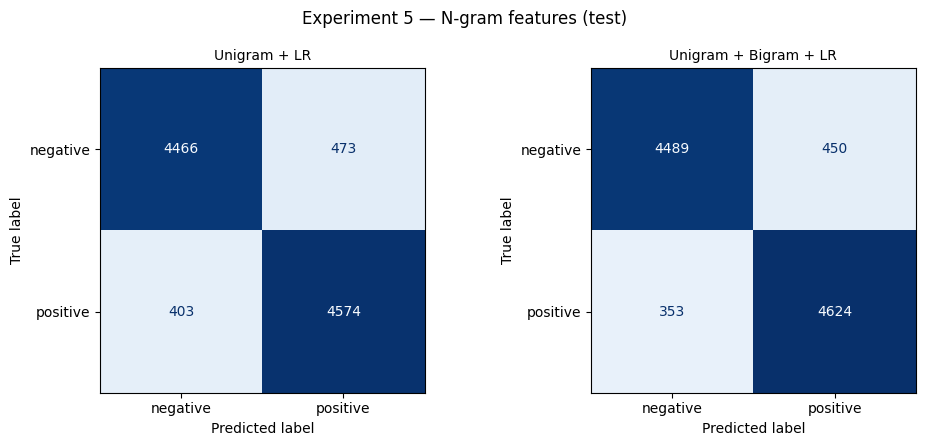

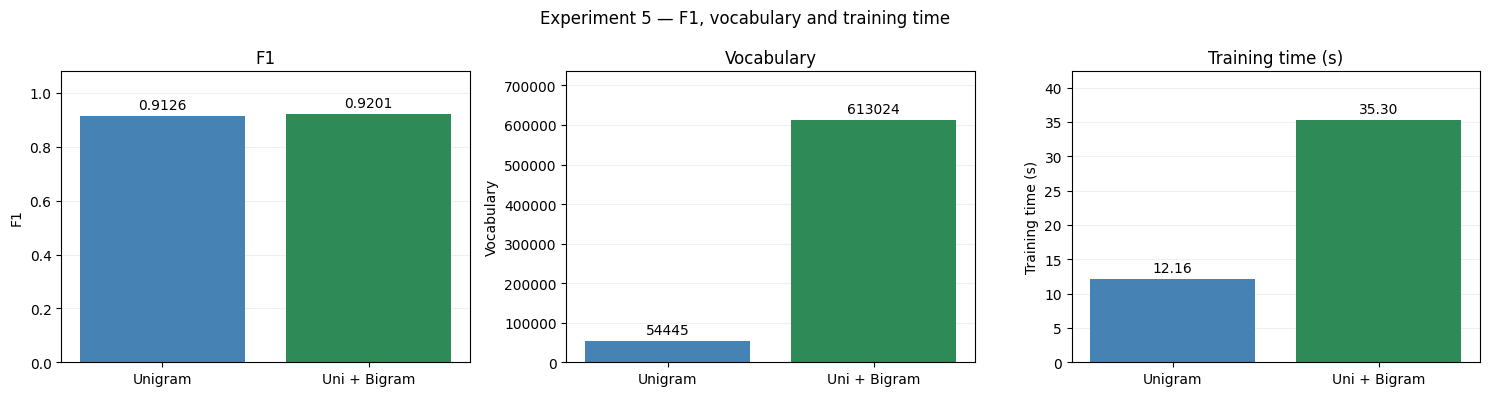

In [42]:
show_confusion_matrices(
    y_test,
    {"Unigram + LR": y_test_pred_unigram, "Unigram + Bigram + LR": y_test_pred_bigram},
    "Experiment 5 — N-gram features (test)"
)
show_result_comparison(
    ngram_results,
    ["Unigram", "Uni + Bigram"],
    "Experiment 5 — F1, vocabulary and training time",
    metrics=("F1", "Vocabulary", "Training time (s)")
)


## Nhận xét Experiment 5 — Vì sao bigram giúp nhưng làm feature space lớn hơn?

Giữ C = 2, min_df = 2, cùng dữ liệu fit/test và classifier, unigram đạt F1 0,9126, còn unigram + bigram đạt 0,9201, tăng khoảng 0,75 điểm phần trăm. Precision tăng 0,9063 → 0,9113, recall tăng 0,9190 → 0,9291, nên F1 tăng cùng với cải thiện cả hai thành phần.

Confusion matrix thay đổi từ `[[4466, 473], [403, 4574]]` sang `[[4489, 450], [353, 4624]]`. FP giảm 23, FN giảm 50, tổng lỗi giảm 876 → 803, tức dự đoán đúng thêm 73 review và giảm tương đối 8,33% số lỗi. Cải thiện lớn hơn ở việc giảm bỏ sót positive trong lần chạy này.

Vocabulary tăng 54.445 → 613.024 feature, thêm 558.579 feature, khoảng 11,26 lần. Unigram tạo feature cho từng token; `ngram_range=(1, 2)` còn tạo feature cho các cặp token đứng cạnh nhau xuất hiện đủ min_df. Corpus có nhiều tổ hợp từ khác nhau nên số feature tăng mạnh, dù không phải mọi cặp trong vocabulary đều được dùng.

Code xác nhận `not good` và `very good` có trong vocabulary bigram. Các phrase này cho phép classifier học tín hiệu riêng thay vì cộng độc lập `not` và `good`. Kết quả F1 và số lỗi phù hợp với lợi ích của phrase features, nhưng chưa chứng minh cả 73 lỗi được sửa đều là lỗi phủ định.

Training time tăng 12,1601 → 35,2952 giây, khoảng 2,90 lần. Đây là đánh đổi giữa chất lượng và chi phí feature extraction, lưu trữ sparse matrix và fit classifier. Feature space tăng 11,26 lần không có nghĩa RAM hoặc thời gian phải tăng đúng 11,26 lần, vì chúng còn phụ thuộc số phần tử khác 0 và thuật toán.

Uni + bigram có test F1 cao nhất trong các cấu hình đã báo cáo. Đây là mô tả kết quả thí nghiệm, không dùng thứ hạng test để quay lại tuning C hoặc min_df.

# Inspect model weights

In [43]:
# Ưu tiên model từ Experiment 3.
# Nếu chưa chạy Experiment 3 thì dùng final_model của Experiment 2.

model_for_interpretation = (
    tfidf_lr_final
    if "tfidf_lr_final" in globals()
    else final_model
)

tfidf_vectorizer = model_for_interpretation.named_steps["tfidf"]
classifier = model_for_interpretation.named_steps["classifier"]

feature_names = tfidf_vectorizer.get_feature_names_out()
raw_weights = classifier.coef_[0]

classes = classifier.classes_
print("Classes:", classes)

# Đưa weight về hướng dự đoán class positive
if classes[1] == "positive":
    positive_weights = raw_weights
else:
    positive_weights = -raw_weights

Classes: ['negative' 'positive']


In [44]:
TOP_K = 20

positive_indices = positive_weights.argsort()[-TOP_K:][::-1]
negative_indices = positive_weights.argsort()[:TOP_K]

top_positive_features = pd.DataFrame({
    "Feature": feature_names[positive_indices],
    "Weight": positive_weights[positive_indices]
})

top_negative_features = pd.DataFrame({
    "Feature": feature_names[negative_indices],
    "Weight": positive_weights[negative_indices]
})

print("Top positive features:")
display(top_positive_features)

print("Top negative features:")
display(top_negative_features)

Top positive features:


,Feature,Weight
0,great,9.656499
1,excellent,8.631345
2,perfect,7.186910
3,amazing,6.548006
4,wonderful,6.403014
5,best,6.312118
6,enjoyed,5.827080
7,loved,5.722328
8,today,5.644433
9,brilliant,5.628531


Top negative features:


,Feature,Weight
0,worst,-13.366251
1,waste,-9.913440
2,awful,-9.557949
3,boring,-9.155955
4,bad,-8.975656
5,terrible,-7.635664
6,poor,-7.530591
7,horrible,-7.119257
8,poorly,-6.580147
9,nothing,-6.399471


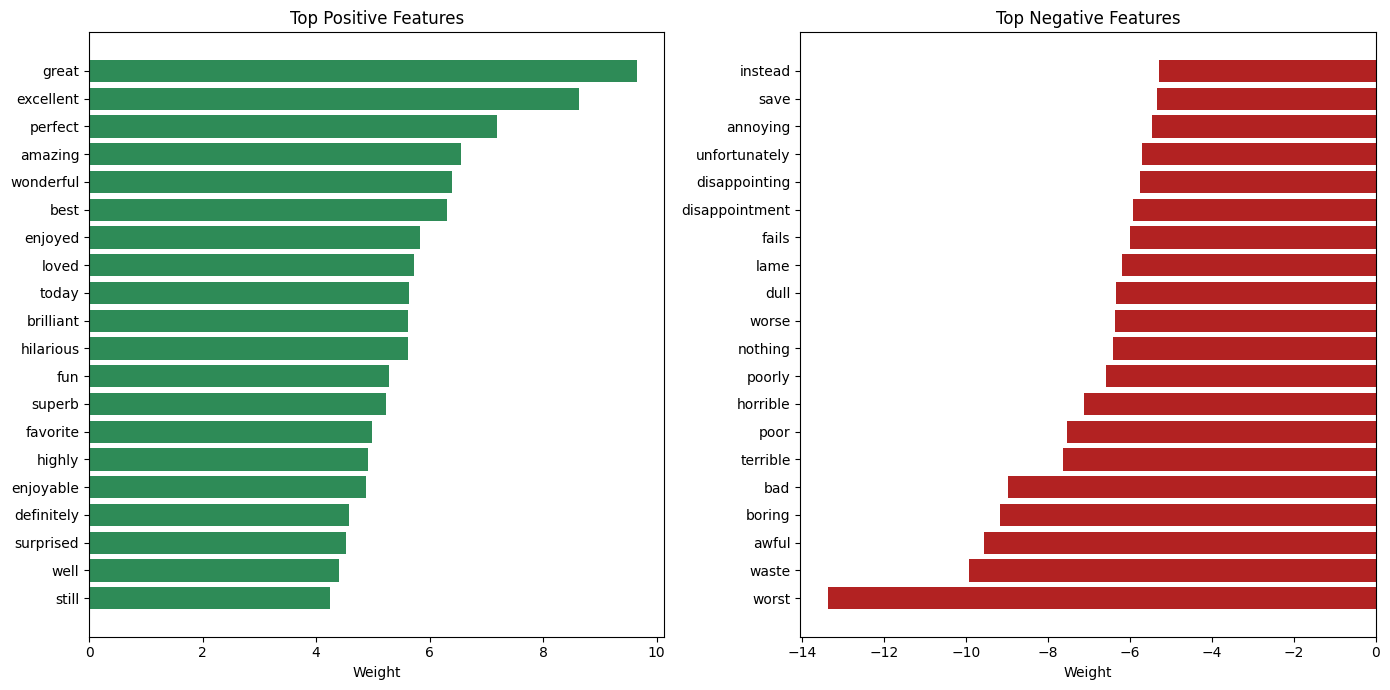

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].barh(
    top_positive_features["Feature"][::-1],
    top_positive_features["Weight"][::-1],
    color="seagreen"
)

axes[0].set_title("Top Positive Features")
axes[0].set_xlabel("Weight")

axes[1].barh(
    top_negative_features["Feature"],
    top_negative_features["Weight"],
    color="firebrick"
)

axes[1].set_title("Top Negative Features")
axes[1].set_xlabel("Weight")

plt.tight_layout()
plt.show()

## Nhận xét model weights — Các feature có ý nghĩa với task không?

Các feature sentiment rõ ràng có hướng trọng số phù hợp:

| Feature | Weight | Hướng đóng góp |
|---|---:|---|
| great | +9,6565 | positive |
| excellent | +8,6313 | positive |
| perfect | +7,1869 | positive |
| worst | −13,3663 | negative |
| waste | −9,9134 | negative |
| awful | −9,5579 | negative |
| boring | −9,1560 | negative |

Các từ khen/chê này phù hợp với sentiment review phim. Tuy nhiên, các feature như `today` (+5,6444), `still` (+4,2498) hoặc `save` (−5,3352) không tự mang sentiment cố định. Weight của chúng có thể phản ánh các ngữ cảnh hoặc tương quan trong corpus; không đủ để nói “today luôn tích cực” hoặc “save luôn tiêu cực”.

Weight là tham số chung của model. Trong một review cụ thể, đóng góp là weight × TF-IDF, và logit là tổng mọi đóng góp cộng bias. Ví dụ, ở review “This movie is terrible but it has some good effects”, `terrible` đóng góp −4,3466, mạnh hơn `good` +1,0274; logit cuối −3,2051 nên model dự đoán negative. Ở review “Great movie…”, `great` đóng góp +1,5327, khác với việc chỉ nhìn weight 9,6565.

Vì vậy, top weights giúp giải thích xu hướng lexical của model, nhưng cần local contributions để giải thích từng dự đoán. Chúng không chứng minh model hiểu ngữ nghĩa hoặc quan hệ nhân quả; unigram còn khó biểu diễn việc sentiment thay đổi trong cụm như `not good` hoặc `not bad`.

# Application

In [46]:
application_model = (
    tfidf_lr_final
    if "tfidf_lr_final" in globals()
    else final_model
)

application_preprocessor = TextPreprocessor()

In [47]:
new_reviews = [
    "This movie was absolutely wonderful and very enjoyable.",
    "The story was boring and the acting was terrible.",
    "I expected much more from this movie.",
    "The actors were excellent and the ending was amazing."
]

application_df = pd.DataFrame({
    "review": new_reviews
})

application_df["text_clean"] = application_df["review"].apply(
    application_preprocessor.clean_text
)

In [48]:
application_df["prediction"] = application_model.predict(
    application_df["text_clean"]
)

display(
    application_df[
        ["review", "prediction"]
    ]
)

,review,prediction
0,This movie was absolutely wonderful and very e...,positive
1,The story was boring and the acting was terrible.,negative
2,I expected much more from this movie.,negative
3,The actors were excellent and the ending was a...,positive


In [49]:
probabilities = application_model.predict_proba(
    application_df["text_clean"]
)

classes = application_model.named_steps[
    "classifier"
].classes_

for i, class_name in enumerate(classes):
    application_df[f"probability_{class_name}"] = (
        probabilities[:, i]
    )

display(application_df)

,review,text_clean,prediction,probability_negative,probability_positive
0,This movie was absolutely wonderful and very e...,this movie was absolutely wonderful and very e...,positive,0.001974,0.998026
1,The story was boring and the acting was terrible.,the story was boring and the acting was terrible.,negative,0.999938,0.000062
2,I expected much more from this movie.,i expected much more from this movie.,negative,0.509570,0.490430
3,The actors were excellent and the ending was a...,the actors were excellent and the ending was a...,positive,0.001248,0.998752


## Application — Prediction probabilities

Mỗi cột là một review minh họa. Hai màu biểu diễn xác suất negative và positive; các review mới chưa có nhãn đúng để tính confusion matrix.


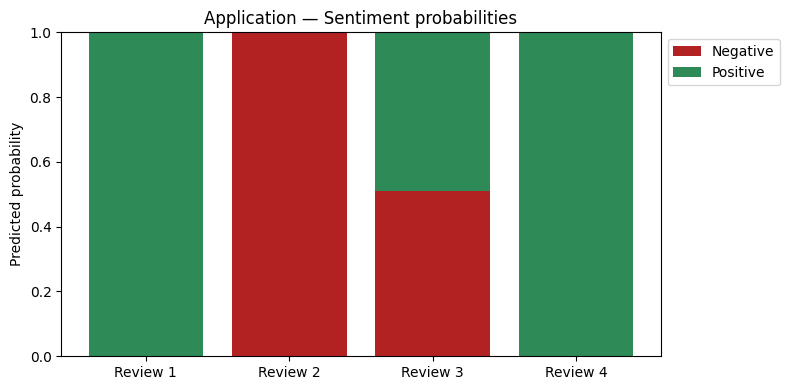

In [50]:
review_ids = [f"Review {i + 1}" for i in range(len(application_df))]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    review_ids, application_df["probability_negative"],
    color="firebrick", label="Negative"
)
ax.bar(
    review_ids, application_df["probability_positive"],
    bottom=application_df["probability_negative"],
    color="seagreen", label="Positive"
)
ax.set_ylim(0, 1)
ax.set_ylabel("Predicted probability")
ax.set_title("Application — Sentiment probabilities")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
plt.show()


## Nhận xét Application — Áp dụng cho review mới

Application hiện dùng TF-IDF + Logistic Regression unigram ở Experiment 3. Các review mới được làm sạch bằng cùng TextPreprocessor rồi transform bằng vocabulary/IDF đã fit; không fit lại trên bốn câu mới.

| Review minh họa | Prediction | P(positive) |
|---|---|---:|
| absolutely wonderful and very enjoyable | positive | 0,998026 |
| boring … acting was terrible | negative | 0,000062 |
| I expected much more from this movie | negative | 0,490430 |
| excellent … ending was amazing | positive | 0,998752 |

Ba câu có từ sentiment trực tiếp được dự đoán theo hướng phù hợp và có điểm số xa threshold. Câu “I expected much more…” thể hiện thất vọng gián tiếp; model chọn negative vì P(positive) 0,490430 < 0,5, nhưng P(negative) chỉ 0,509570. Đây là trường hợp sát boundary, không nên mô tả là dự đoán negative chắc chắn.

Bốn câu chỉ kiểm tra thao tác inference và quan sát hành vi. Chúng chưa có bộ nhãn độc lập để đánh giá định lượng, nên không thể từ bốn prediction này báo accuracy 100% hay kết luận model xử lý tốt mọi cách diễn đạt. `predict_proba` là xác suất ước lượng của model; notebook chưa kiểm tra calibration để xác nhận các giá trị này là độ tin cậy thực nghiệm.

# Evaluation — Model for error analysis

Chọn prediction đã lưu của TF-IDF + Logistic Regression để xem các mẫu đúng/sai. Confusion matrix của các model nằm ngay trong từng experiment.

In [51]:
analysis_model_name = "TF-IDF + Logistic Regression"

if "y_test_predictions" in globals():
    analysis_y_pred = y_test_predictions[analysis_model_name]
else:
    analysis_y_pred = y_test_pred

print("Model for error analysis:", analysis_model_name)

Model for error analysis: TF-IDF + Logistic Regression


## Trả lời câu hỏi Evaluation — Class nào bị nhầm nhiều, lỗi nào chiếm nhiều?

Confusion matrix sử dụng **hàng = nhãn đúng**, **cột = nhãn dự đoán**, theo thứ tự negative rồi positive: `[[TN, FP], [FN, TP]]`. Positive là review tích cực, nên FP là gán tích cực cho một review negative; FN là bỏ sót một review positive.

| Model | FP | FN | Tổng lỗi | Recall negative | Recall positive |
|---|---:|---:|---:|---:|---:|
| TF-IDF + LR unigram | 473 | 403 | 876 | 90,42% | 91,90% |
| Average Word2Vec + LR | 599 | 579 | 1.178 | 87,87% | 88,37% |
| TF-IDF + Linear SVM | 463 | 405 | 868 | 90,63% | 91,86% |
| TF-IDF uni + bigram + LR | 450 | 353 | 803 | 90,89% | 92,91% |

Ở TF-IDF + LR, negative bị nhầm thành positive 473/4.939 ≈ 9,58%, còn positive bị nhầm thành negative 403/4.977 ≈ 8,10%. Negative khó được nhận diện đúng hơn một chút. Điều này không chỉ do số mẫu: support của hai lớp gần bằng nhau.

Metric phản ánh vấn đề: positive precision 4574/(4574+473) = 0,9063 phản ánh positive predictions bị lẫn negative; negative recall 4466/(4466+473) = 0,9042 phản ánh khả năng nhận diện negative. Positive recall 4574/(4574+403) = 0,9190 phản ánh số positive được tìm thấy và mức bỏ sót FN. Chỉ nhìn accuracy 0,9117 sẽ không thấy rõ hai hướng lỗi này.

F1 positive 0,9126 hơi cao hơn F1 negative 0,9107, nên Macro F1 khoảng 0,9116. Macro F1 gần accuracy và F1 positive vì dữ liệu khá cân bằng và hai lớp không có khoảng cách hiệu năng lớn. Với Word2Vec, cả hai recall đều giảm, phù hợp với việc lỗi tăng lên 1.178 thay vì chỉ thất bại ở một lớp.

# Error analysis

Chọn 3 mẫu đúng và 3 mẫu sai; ưu tiên có cả positive và negative trong mỗi nhóm nếu dữ liệu có đủ. Các mẫu ngắn giúp đọc thuận tiện, không đại diện cho tỷ lệ lỗi toàn bộ test.

TP/TN là mẫu đúng; FP là negative bị dự đoán positive, FN là positive bị dự đoán negative. Tự điền `Error type` và `Analysis` sau khi đọc văn bản và đóng góp feature bên dưới.

In [52]:
# Giữ index để đối chiếu đúng review, nhãn và prediction.
error_table = pd.DataFrame({
    "Text": df.loc[X_test.index, "text"],
    "Text clean": X_test,
    "True label": y_test.reindex(X_test.index),
    "Predicted label": pd.Series(analysis_y_pred, index=X_test.index)
})
error_table["Correct"] = error_table["True label"].eq(error_table["Predicted label"])
error_table["Outcome"] = np.select(
    [
        error_table["Correct"] & error_table["True label"].eq("positive"),
        error_table["Correct"] & error_table["True label"].eq("negative"),
        ~error_table["Correct"] & error_table["True label"].eq("negative")
    ],
    ["TP", "TN", "FP"],
    default="FN"
)
error_table["Token count"] = error_table["Text clean"].map(
    lambda text: len(preprocessor.tokenize(text))
)

selected_indices = []
for is_correct in [True, False]:
    pool = error_table.loc[error_table["Correct"].eq(is_correct)].sort_values(
        "Token count", kind="stable"
    )
    group_indices = []
    for label in LABEL_ORDER:
        matches = pool.loc[pool["True label"].eq(label)]
        if not matches.empty:
            group_indices.append(matches.index[0])
    remaining = [index for index in pool.index if index not in group_indices]
    group_indices.extend(remaining[:max(0, 3 - len(group_indices))])
    selected_indices.extend(group_indices)

error_analysis = error_table.loc[selected_indices].copy()
error_analysis.insert(0, "Review index", error_analysis.index)
error_analysis = error_analysis.reset_index(drop=True)
error_analysis["Error type"] = ""
error_analysis["Analysis"] = ""
display_columns = [
    "Review index", "Text", "True label", "Predicted label",
    "Outcome", "Token count", "Error type", "Analysis"
]
with pd.option_context("display.max_colwidth", 140):
    display(error_analysis[display_columns])
print("Correct/incorrect examples:", error_analysis["Correct"].value_counts().to_dict())

,Review index,Text,True label,Predicted label,Outcome,Token count,Error type,Analysis
0,40541,I hope this group of film-makers never re-unites.,negative,negative,TN,10,,
1,39769,"Without a doubt, one of Tobe Hoppor's best! Epic storytellng, great special effects, and The Spacegirl (vamp me baby!).",positive,positive,TP,19,,
2,19802,This movie is terrible but it has some good effects.,negative,negative,TN,10,,
3,31585,Ming The Merciless does a little Bardwork and a movie most foul!,negative,positive,FP,12,,
4,12187,"It's not Citizen Kane, but it does deliver. Cleavage, and lots of it.<br /><br />Badly acted and directed, poorly scripted. Who cares? I...",positive,negative,FN,28,,
5,14877,"Great movie - especially the music - Etta James - ""At Last"". This speaks volumes when you have finally found that special someone.",negative,positive,FP,20,,


Correct/incorrect examples: {True: 3, False: 3}


## Error analysis — Đóng góp feature của từng review

Weight là đặc điểm chung của model; contribution = weight × TF-IDF mới là đóng góp trong review cụ thể. Tổng contribution cộng bias tạo logit. Bảng dưới chỉ hỗ trợ đọc bằng chứng; tự xác định nguyên nhân lỗi và điền phần phân tích.

In [53]:
def inspect_review_contributions(model, cleaned_text, top_k=8):
    vectorizer = model.named_steps["tfidf"]
    classifier = model.named_steps["classifier"]
    vector = vectorizer.transform([cleaned_text]).tocsr()
    names = vectorizer.get_feature_names_out()

    # Đưa logit và weight về hướng positive, kể cả khi thứ tự class đổi.
    direction = 1.0 if classifier.classes_[1] == "positive" else -1.0
    weights = classifier.coef_[0] * direction
    bias = float(classifier.intercept_[0] * direction)
    contributions = vector.data * weights[vector.indices]
    logit = float(contributions.sum() + bias)
    probability = float(1 / (1 + np.exp(-np.clip(logit, -700, 700))))
    order = np.argsort(-np.abs(contributions), kind="stable")[:top_k]
    evidence = pd.DataFrame({
        "Feature": names[vector.indices[order]],
        "TF-IDF": vector.data[order],
        "Weight": weights[vector.indices[order]],
        "Contribution": contributions[order]
    })
    return evidence, logit, probability

analysis_model = tfidf_lr_final if "tfidf_lr_final" in globals() else final_model
for case_id, row in error_analysis.iterrows():
    evidence, logit, probability = inspect_review_contributions(
        analysis_model, row["Text clean"]
    )
    error_analysis.loc[case_id, "P(positive)"] = probability
    print(
        f"\nExample {case_id + 1} — {row['Outcome']} — "
        f"true={row['True label']}, predicted={row['Predicted label']}"
    )
    print(f"Logit={logit:.4f}; P(positive)={probability:.4f}")
    print(row["Text"])
    display(evidence.round(4))


Example 1 — TN — true=negative, predicted=negative
Logit=-1.4367; P(positive)=0.1921
I hope this group of film-makers never re-unites.


,Feature,TF-IDF,Weight,Contribution
0,makers,0.3946,-1.7322,-0.6836
1,re,0.2326,-1.7846,-0.4151
2,hope,0.3064,0.9507,0.2913
3,group,0.3310,-0.7281,-0.2410
4,never,0.2025,-0.9645,-0.1953
5,this,0.0851,-1.3057,-0.1111
6,film,0.1228,0.8607,0.1057
7,unites,0.7189,-0.1275,-0.0917



Example 2 — TP — true=positive, predicted=positive
Logit=2.5535; P(positive)=0.9278
Without a doubt, one of Tobe Hoppor's best! Epic storytellng, great special effects, and The Spacegirl (vamp me baby!).


,Feature,TF-IDF,Weight,Contribution
0,great,0.1472,9.6565,1.4218
1,best,0.1635,6.3121,1.0321
2,baby,0.3085,-0.8069,-0.2490
3,and,0.0641,3.0170,0.1934
4,epic,0.3395,0.5679,0.1928
5,special,0.2245,0.7705,0.1730
6,effects,0.2231,-0.7432,-0.1658
7,doubt,0.2817,-0.5515,-0.1554



Example 3 — TN — true=negative, predicted=negative
Logit=-3.2051; P(positive)=0.0390
This movie is terrible but it has some good effects.


...

,Feature,TF-IDF,Weight,Contribution
0,most,0.1659,2.6008,0.4315
1,ming,0.5878,0.7314,0.4299
2,foul,0.4670,-0.7091,-0.3312
3,and,0.0730,3.0170,0.2203
4,does,0.1925,-0.9758,-0.1878
5,little,0.1884,0.7231,0.1362
6,merciless,0.5611,0.1801,0.1011
7,the,0.0712,0.6344,0.0452



Example 5 — FN — true=positive, predicted=negative
Logit=-2.1290; P(positive)=0.1063
It's not Citizen Kane, but it does deliver. Cleavage, and lots of it.<br /><br />Badly acted and directed, poorly scripted. Who cares? I didn't watch it for the dialog.


,Feature,TF-IDF,Weight,Contribution
0,poorly,0.2265,-6.5801,-1.4907
1,badly,0.2301,-4.8680,-1.1203
2,it,0.2148,3.6743,0.7891
3,dialog,0.2204,-1.3860,-0.3055
4,didn,0.1434,-2.1167,-0.3036
5,and,0.0996,3.0170,0.3006
6,not,0.0730,-3.5768,-0.2612
7,kane,0.3051,0.7899,0.2410



Example 6 — FP — true=negative, predicted=positive
Logit=2.7954; P(positive)=0.9424
Great movie - especially the music - Etta James - "At Last". This speaks volumes when you have finally found that special someone.


,Feature,TF-IDF,Weight,Contribution
0,great,0.1587,9.6565,1.5327
1,especially,0.2277,3.9615,0.9020
2,someone,0.2378,-2.2671,-0.5391
3,music,0.2230,1.5931,0.3553
4,you,0.1069,3.0278,0.3236
5,james,0.3005,0.7301,0.2194
6,found,0.2281,-0.9581,-0.2185
7,speaks,0.3927,-0.5354,-0.2102


## Phân tích cụ thể 3 mẫu đúng và 3 mẫu sai

Các review và nhãn dưới đây đã được đối chiếu lại với corpus sau cùng cách làm sạch/dedup. Đây là các ví dụ ngắn để giải thích hành vi; không dùng sáu mẫu này để ước lượng tỷ lệ các nguyên nhân lỗi trên toàn bộ test.

| Ví dụ | Review index | True → Predicted | Outcome | P(positive) | Nhóm phân tích |
|---|---:|---|---|---:|---|
| 1 | 40541 | negative → negative | TN | 0,1921 | Đúng; sắc thái phủ định |
| 2 | 39769 | positive → positive | TP | 0,9278 | Đúng; từ khen rõ ràng, có từ hiếm |
| 3 | 19802 | negative → negative | TN | 0,0390 | Đúng; review có cả ý khen/chê |
| 4 | 31585 | negative → positive | FP | 0,6743 | Short text; rare/domain-specific term; phrase bị tách |
| 5 | 12187 | positive → negative | FN | 0,1063 | Mixed sentiment; negation/context |
| 6 | 14877 | negative → positive | FP | 0,9424 | Nghi vấn data noise / nhãn không nhất quán |

### Ví dụ 1 — “I hope this group of film-makers never re-unites.”

Ý kiến mong nhóm làm phim không tái hợp mang sắc thái chê. Model dự đoán đúng negative với logit −1,4367. Các đóng góp âm nổi bật là `makers` −0,6836, `re` −0,4151, `group` −0,2410, `never` −0,1953; `hope` lại góp dương +0,2913. Điều này cho thấy model không chỉ thấy “hope” rồi gán positive. Tuy nhiên, phần lớn tín hiệu âm đến từ các term riêng lẻ, nên dự đoán đúng chưa chứng minh model hiểu toàn bộ ý nghĩa “never re-unites”.

### Ví dụ 2 — “Without a doubt … best! … great special effects …”

Các cụm khen “best” và “great special effects” phù hợp với nhãn positive. `great` đóng góp +1,4218, `best` +1,0321, vượt các đóng góp âm như `baby` −0,2490 và `effects` −0,1658. Logit 2,5535 cho P(positive) 0,9278. Kiểm tra corpus cho thấy `hoppor` và `storytellng` mỗi từ chỉ có trong một document; với min_df = 2, chúng không thể vào vocabulary TF-IDF đã fit. Model vẫn đúng nhờ các từ khen phổ biến, cho thấy một vài từ hiếm/misspelling không nhất thiết gây lỗi nếu tín hiệu khác đủ mạnh.

### Ví dụ 3 — “This movie is terrible but it has some good effects.”

Review chê phim nhưng khen một khía cạnh. `terrible` đóng góp −4,3466, lớn hơn đáng kể đóng góp `good` +1,0274. Logit cuối −3,2051, P(positive) 0,0390, nên negative phù hợp với nhãn và ý chính của câu. Model xử lý được ví dụ có ý kiến trái chiều này nhờ tổng trọng số nghiêng âm, nhưng không có bằng chứng nó hiểu quan hệ tương phản do “but”; ví dụ 5 cho thấy cách cộng tín hiệu này cũng có thể dẫn đến lỗi.

### Ví dụ 4 — “Ming The Merciless … Bardwork … a movie most foul!”

Cụm “movie most foul” mang sắc thái tiêu cực nhưng model cho positive. `foul` góp âm −0,3312, trong khi `most` +0,4315, `ming` +0,4299, `and` +0,2203 cùng các feature khác làm logit đạt 0,7277. Unigram tách “most” khỏi “foul”, nên “most” được dùng với weight dương chung thay vì biểu diễn cả phrase chê phim. Review chỉ có **12 token**, chứa tên riêng và từ ít thông dụng; `bardwork` chỉ xuất hiện ở một document của toàn corpus, nên bị loại bởi min_df = 2. Nhóm lỗi phù hợp là **short text + rare/domain-specific term + hạn chế của lexical phrase**. Từ hiếm bị loại là bằng chứng mất feature, nhưng chưa thể khẳng định giữ riêng từ đó chắc chắn sửa được prediction.

### Ví dụ 5 — “It's not Citizen Kane, but it does deliver … Badly acted … poorly scripted … I didn't watch it for the dialog.”

Nhãn positive có thể hiểu từ việc tác giả vẫn đánh giá phim đáp ứng điều mình mong đợi, dù thừa nhận hạn chế về diễn xuất, đạo diễn và kịch bản. Model bị các từ chê kéo về negative: `poorly` **−1,4907**, `badly` **−1,1203**, `dialog` **−0,3055**, `didn` **−0,3036**, `not` **−0,2612**. Logit **−2,1290** cho P(positive) **0,1063**. Cấu trúc “not Citizen Kane, but it does deliver” và “didn't watch it for the dialog” cần hiểu ngữ cảnh/tiêu chí đánh giá, không thể suy sentiment chỉ từ sự xuất hiện của “not”, “badly”, “poorly”. Nhóm lỗi là **mixed sentiment và negation/context**, không phải class imbalance.

### Ví dụ 6 — “Great movie — especially the music … finally found that special someone.”

Review mở đầu bằng “Great movie”, khen âm nhạc và diễn đạt tích cực, nhưng nhãn nguồn lại là **negative**. Đã đối chiếu corpus để xác nhận đây đúng là nhãn nguồn, không phải lỗi lệch index khi dựng bảng. Model dự đoán positive với logit **2,7954**: `great` **+1,5327**, `especially` **+0,9020**, `music` **+0,3553** là các đóng góp dương đáng kể.

Theo nhãn dataset, đây vẫn là **FP** và được tính vào metrics. Theo nội dung hiện có, **nhiễu nhãn/nhãn không nhất quán là một khả năng cần kiểm tra**; chưa đủ thông tin để khẳng định nhãn chắc chắn sai hoặc câu chắc chắn là sarcasm. Cần kiểm tra lại nguồn annotation/ngữ cảnh nếu muốn kết luận nguyên nhân. Trong thí nghiệm này giữ nguyên nhãn test và báo cáo sự không chắc chắn, không tự đổi nhãn để cải thiện score.

### Điều rút ra từ các lỗi

Không phải mọi mẫu lệch nhãn đều có cùng nguyên nhân. Ví dụ 4 thiếu thông tin lexical/phrase trong câu ngắn; ví dụ 5 có ý kiến trái chiều và ngữ cảnh phủ định; ví dụ 6 cần kiểm tra chất lượng nhãn. Local contributions giải thích cơ chế đẩy điểm số của classifier, còn xác định nguyên nhân ngữ nghĩa là lập luận từ review và có mức độ chắc chắn khác nhau. Sự có mặt của một từ phủ định hay từ hiếm riêng lẻ không đủ để tự động gán nguyên nhân lỗi.

# Final results export

Một file `results.csv` chứa các bảng kết quả experiment và ablation trên validation. `Split` phân biệt Test, Validation và Probe; F1 là F1 của positive, Macro F1 là trung bình hai lớp. Training time chỉ tính fit representation và classifier. Các hình hiển thị trong notebook.

In [54]:
def result_row(
    experiment, model_name, features, predictions, timing,
    vocabulary_size, C, min_df=None, embedding_dim=None
):
    is_tfidf = "TF-IDF" in model_name
    return {
        "Experiment": experiment,
        "Result type": "metrics",
        "Split": "Test",
        "Model": model_name,
        "Representation": "TF-IDF" if is_tfidf else "Average Word2Vec",
        "Classifier": "Linear SVM" if "SVM" in model_name else "Logistic Regression",
        "Features": features,
        "C": C,
        "min_df": min_df,
        "Embedding dimension": embedding_dim,
        "Vocabulary size": vocabulary_size,
        "Feature count": vocabulary_size if is_tfidf else embedding_dim,
        **timing,
        **compute_metrics(y_test, predictions)
    }

results_rows = [
    result_row(
        "Experiment 2 - Baseline", "TF-IDF + Logistic Regression", "Unigram",
        y_test_pred, baseline_timing, vocabulary_size, best_C, best_min_df
    ),
    result_row(
        "Experiment 3 - Representation comparison", "TF-IDF + Logistic Regression", "Unigram",
        y_test_predictions["TF-IDF + Logistic Regression"],
        training_breakdown["TF-IDF + Logistic Regression"],
        len(tfidf_lr_final.named_steps["tfidf"].vocabulary_), best_lr_C, best_lr_min_df
    ),
    result_row(
        "Experiment 3 - Representation comparison", "Average Word2Vec + Logistic Regression", "Average embeddings",
        y_test_predictions["Average Word2Vec + Logistic Regression"],
        training_breakdown["Average Word2Vec + Logistic Regression"],
        len(w2v_final_model.wv), best_w2v_C, embedding_dim=w2v_final_model.vector_size
    ),
    result_row(
        "Experiment 3 - Representation comparison", "TF-IDF + Linear SVM", "Unigram",
        y_test_predictions["TF-IDF + Linear SVM"],
        training_breakdown["TF-IDF + Linear SVM"],
        len(tfidf_svm_final.named_steps["tfidf"].vocabulary_), best_svm_C, best_svm_min_df
    ),
    result_row(
        "Experiment 5 - N-gram features", "TF-IDF + Logistic Regression", "Unigram",
        y_test_pred_unigram, unigram_timing, unigram_vocab_size, EXPERIMENT_C, MIN_DF
    ),
    result_row(
        "Experiment 5 - N-gram features", "TF-IDF + Logistic Regression", "Unigram + Bigram",
        y_test_pred_bigram, bigram_timing, bigram_vocab_size, EXPERIMENT_C, MIN_DF
    )
]

for row in ablation_results.to_dict("records"):
    results_rows.append({
        "Experiment": "Ablation - Vocabulary and stopwords",
        "Result type": "metrics",
        "Split": "Validation",
        **row
    })

# Probe chỉ có prediction/xác suất, không có nhãn đúng để tính metrics.
for row_idx, row in experiment4_results.iterrows():
    results_rows.append({
        "Experiment": "Experiment 4 - Word order",
        "Result type": "word_order",
        "Split": "Probe",
        "Model": "Average Word2Vec + Logistic Regression",
        "Representation": "Average Word2Vec",
        "Classifier": "Logistic Regression",
        "Features": row["Sentence ID"],
        "Sentence": row["Sentence"],
        "Prediction": row["Prediction"],
        "TF-IDF prediction": row["TF-IDF prediction"],
        "Negative probability": row["Negative probability"],
        "Positive probability": row["Positive probability"],
        "TF-IDF positive probability": row["TF-IDF positive probability"],
        "Cosine similarity to S1": float(similarity_matrix[0, row_idx])
    })

results = pd.DataFrame(results_rows)
results["Seed"] = RANDOM_SEED
results["Train samples"] = len(X_train)
results["Validation samples"] = len(X_valid)
results["Test samples"] = len(X_test)
results["Fit samples"] = results["Split"].map({
    "Test": len(X_train_final), "Validation": len(X_train)
})
integer_columns = [
    "Vocabulary size", "Feature count", "Embedding dimension",
    "TN", "FP", "FN", "TP", "Fit samples", "Max features", "min_df"
]
for column in integer_columns:
    if column in results:
        results[column] = results[column].astype("Int64")
results = results.round(4)
results_path = LAB_DIR / "results.csv"
results.to_csv(results_path, index=False, encoding="utf-8-sig")
display(results)
print(f"Saved {len(results)} experiment result rows to: {results_path}")

,Experiment,Result type,Split,Model,Representation,Classifier,Features,C,min_df,Embedding dimension,...,TF-IDF prediction,Negative probability,Positive probability,TF-IDF positive probability,Cosine similarity to S1,Seed,Train samples,Validation samples,Test samples,Fit samples
0,Experiment 2 - Baseline,metrics,Test,TF-IDF + Logistic Regression,TF-IDF,Logistic Regression,Unigram,2.0,2,<NA>,...,NaN,NaN,NaN,NaN,NaN,2026,29746,9916,9916,39662
1,Experiment 3 - Representation comparison,metrics,Test,TF-IDF + Logistic Regression,TF-IDF,Logistic Regression,Unigram,2.0,2,<NA>,...,NaN,NaN,NaN,NaN,NaN,2026,29746,9916,9916,39662
2,Experiment 3 - Representation comparison,metrics,Test,Average Word2Vec + Logistic Regression,Average Word2Vec,Logistic Regression,Average embeddings,10.0,<NA>,100,...,NaN,NaN,NaN,NaN,NaN,2026,29746,9916,9916,39662
3,Experiment 3 - Representation comparison,metrics,Test,TF-IDF + Linear SVM,TF-IDF,Linear SVM,Unigram,0.5,2,<NA>,...,NaN,NaN,NaN,NaN,NaN,2026,29746,9916,9916,39662
4,Experiment 5 - N-gram features,metrics,Test,TF-IDF + Logistic Regression,TF-IDF,Logistic Regression,Unigram,2.0,2,<NA>,...,NaN,NaN,NaN,NaN,NaN,2026,29746,9916,9916,39662
5,Experiment 5 - N-gram features,metrics,Test,TF-IDF + Logistic Regression,TF-IDF,Logistic Regression,Unigram + Bigram,2.0,2,<NA>,...,NaN,NaN,NaN,NaN,NaN,2026,29746,9916,9916,39662
6,Ablation - Vocabulary and stopwords,metrics,Validation,5k — keep stopwords,TF-IDF,Logistic Regression,Unigram,2.0,2,<NA>,...,NaN,NaN,NaN,NaN,NaN,2026,29746,9916,9916,29746
7,Ablation - Vocabulary and stopwords,metrics,Validation,10k — keep stopwords,TF-IDF,Logistic Regression,Unigram,2.0,2,<NA>,...,NaN,NaN,NaN,NaN,NaN,2026,29746,9916,9916,29746
8,Ablation - Vocabulary and stopwords,metrics,Validation,20k — keep stopwords,TF-IDF,Logistic Regression,Unigram,2.0,2,<NA>,...,NaN,NaN,NaN,NaN,NaN,2026,29746,9916,9916,29746
9,Ablation - Vocabulary and stopwords,metrics,Validation,10k — remove stopwords,TF-IDF,Logistic Regression,Unigram,2.0,2,<NA>,...,NaN,NaN,NaN,NaN,NaN,2026,29746,9916,9916,29746


Saved 13 experiment result rows to: D:\Study\Study_Class\Semester_7\NLP\Lab\lab04\results.csv


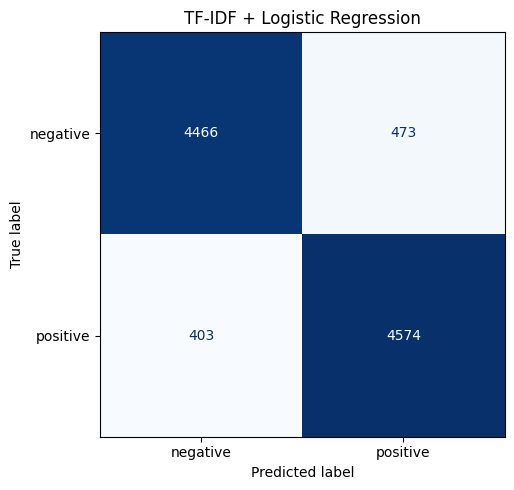

Đã lưu ảnh tại: D:\Study\Study_Class\Semester_7\NLP\Lab\lab04\confusion_matrix.png


In [55]:
cm_model_name = "TF-IDF + Logistic Regression"
cm_save_path = LAB_DIR / "confusion_matrix.png"

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_predictions[cm_model_name],
    labels=["negative", "positive"],
    display_labels=["negative", "positive"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=ax
)

ax.set_title(cm_model_name)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

fig.tight_layout()
fig.savefig(cm_save_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Đã lưu ảnh tại: {cm_save_path}")

# Kết luận và đối chiếu các câu hỏi sau thực nghiệm

**TF-IDF + Logistic Regression có hoạt động tốt không?** Trong split này, baseline đạt accuracy **91,17%**, F1 positive **91,26%** và Macro F1 **91,16%**, cao hơn nhiều mốc dự đoán một lớp khoảng 50,19%. Tuy vậy, còn 876 lỗi và có các ví dụ khó về phrase, mixed sentiment và ngữ cảnh, nên “hoạt động tốt” không đồng nghĩa hiểu đầy đủ ngôn ngữ.

**Average Word2Vec có chắc chắn tốt hơn TF-IDF không?** Không. Ở cấu hình đã chạy, F1 của Word2Vec **0,8819** thấp hơn TF-IDF **0,9126**, dù coverage cao. Word2Vec lại phản ứng phù hợp với “not good” trong probe. Cần phân biệt chất lượng trung bình trên 9.916 test review với hành vi ở một câu ngắn; một ví dụ đúng không làm model trở thành tốt nhất toàn bộ task.

**Vocabulary lớn hơn có chắc chắn tăng performance không?** 5k → 20k giúp ở ablation, nhưng 20k có validation F1 hơi cao hơn cấu hình uncapped cùng C/min_df. Thêm feature có thể giữ thêm tín hiệu hữu ích hoặc thêm thông tin ít liên quan; dữ liệu lần này không hỗ trợ quy tắc “càng nhiều feature càng tốt”.

**Bỏ stopwords có chắc chắn tốt hơn không?** Không trong ablation 10k này: validation F1 giảm khoảng **0,0042** và thêm **44 lỗi**. `not` bị loại, nhưng đây chỉ là một thay đổi trong cả stopword policy, không phải bằng chứng duy nhất về nguyên nhân giảm.

**Accuracy và F1 có thể cho kết luận khác nhau không?** Có thể, nhưng trong các pipeline của notebook này chúng có cùng xu hướng xếp hạng. Dữ liệu gần cân bằng làm accuracy, Macro F1 và F1 positive tương đối gần nhau. Ở một dataset giả sử có 95% negative và model luôn dự đoán negative, accuracy sẽ là 95% nhưng recall/F1 positive bằng 0. Đó là lý do vẫn phải báo cáo metric từng class và confusion matrix; không áp dụng câu “accuracy cao do imbalance” một cách máy móc cho IMDb hiện tại.

**Kết luận chung:** Trong các cấu hình đã báo cáo, unigram + bigram + LR có test F1 cao nhất **0,9201** và ít lỗi nhất **803**, đổi lại vocabulary lớn hơn 11,26 lần và thời gian fit lâu hơn 2,90 lần so với unigram ở cùng experiment. SVM chỉ nhỉnh hơn LR 8 review; chưa đủ bằng chứng về ưu thế ổn định. Những cải thiện tiếp theo nên được đặt thành thí nghiệm trên train/validation, đặc biệt xử lý negation/phrase, kiểm tra annotation và thử representation giữ ngữ cảnh; không điều chỉnh ngược theo test đã xem.